# Constrained planar five-link closed-chain mechanism

This notebook derives and simulates a planar mechanism made of five rigid links. Each link has center-of-mass coordinates `(x, y)` and orientation `theta`, so the generalized coordinate vector is `q in R^15`. Five revolute pins connect the links around one perimeter loop; link 4 is fixed horizontally. The grounded mechanism has 13 independent scalar constraints and two remaining degrees of freedom.

The notebook builds the holonomic residual `Phi(q)`, derives its Jacobian `J(q)`, forms the acceleration-level constrained dynamics, projects the initial state onto the constraint manifold, and integrates for ten seconds. It then visualizes and exports the trajectory. The time integrator is `solve_ivp` applied to an acceleration-level KKT solve with Baumgarte stabilization; this is a practical ODE treatment of the constrained equations, not a dedicated DAE solver.

Run the notebook from top to bottom. The code is broken into small cells so the geometry, constraint kinematics, dynamic solve, initial-state correction, time integration, visualization, and movie export can each be inspected independently.

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

np.set_printoptions(precision=5, suppress=True)

## Coordinates, energies, and pin constraints

For body `i`, the three generalized coordinates are its center-of-mass position and orientation:

$$q_i = [x_i, y_i, \theta_i]^T, \qquad q = [q_1^T, \ldots, q_5^T]^T \in \mathbb{R}^{15}.$$

The velocity and acceleration vectors use the same coordinate order:

$$\dot q = [\dot x_1,\dot y_1,\dot\theta_1,\ldots,\dot x_5,\dot y_5,\dot\theta_5]^T, \qquad
\ddot q = [\ddot x_1,\ddot y_1,\ddot\theta_1,\ldots,\ddot x_5,\ddot y_5,\ddot\theta_5]^T.$$

The SymPy components use the matching names `x1`, `y1`, `theta1`, `x_dot1`, `y_dot1`, `theta_dot1`, `x_ddot1`, `y_ddot1`, and `theta_ddot1` for each link. The Baumgarte tuning frequency is separately denoted by `omega` and is not a link angular velocity.

The model assumes each body is planar and rigid, and each body frame is attached at its center of mass. With constant mass and planar moment of inertia, the kinetic energy is

$$T = \frac12 \sum_i \left[m_i(\dot{x}_i^2+\dot{y}_i^2)+I_i\dot{\theta}_i^2\right]
= \frac12\dot q^T M\dot q,$$

where `M` is the constant diagonal matrix `diag(m1,m1,I1,...,m5,m5,I5)`. Taking vertical position `y` positive upward, gravity has potential energy `V = sum_i m_i g y_i`, so the generalized gravity force is `Q_g = -dV/dq`; its `y_i` entry is `-m_i g` and its other entries are zero. There are no velocity-dependent inertial terms in these center-of-mass coordinates.

A revolute (pin) joint joins one point fixed in body `a` to one point fixed in body `b`. Let `s_a` and `s_b` be those attachment coordinates expressed in their respective body frames. Define

$$A(\theta)=\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix},
\qquad r_a(q)=p_a+A(\theta_a)s_a,$$

with `p_a = [x_a,y_a]^T` (and similarly for body `b`). A pin means the two world points coincide. It gives **two scalar holonomic constraints**:

$$\Phi_{ab}(q)=r_a(q)-r_b(q)=0.$$

Thus five pins give ten scalar equations; grounding a body pose adds three more. The number of equations alone does not establish mobility: inspect the rank of `J = dPhi/dq` at the configuration. The code below constructs each residual and its analytical Jacobian.

In [23]:
def rotation(theta):
    """Planar rotation matrix from a body frame to the world frame."""
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s], [s, c]])


# S generates a 90-degree rotation, so d(A @ s)/dtheta = S @ A @ s.
S = np.array([[0.0, -1.0], [1.0, 0.0]])


class PinConstraintModel:
    """Rigid-body kinematics and holonomic pin/fixed-pose constraints."""

    def __init__(self, masses, inertias, joints, gravity=9.81, fixed_bodies=None):
        self.masses = np.asarray(masses, dtype=float)
        self.inertias = np.asarray(inertias, dtype=float)
        self.joints = joints
        self.n_bodies = len(self.masses)
        self.gravity = float(gravity)
        self.fixed_bodies = {
            int(body): np.asarray(pose, dtype=float).copy()
            for body, pose in (fixed_bodies or {}).items()
        }
        if self.inertias.shape != self.masses.shape:
            raise ValueError('masses and inertias must have the same length')
        if np.any(self.masses <= 0) or np.any(self.inertias <= 0):
            raise ValueError('masses and inertias must be positive')
        for body, pose in self.fixed_bodies.items():
            if not 0 <= body < self.n_bodies or pose.shape != (3,):
                raise ValueError('fixed bodies need a valid index and an (x, y, theta) pose')
        for body_a, body_b, point_a, point_b in joints:
            if body_a == body_b:
                raise ValueError('a pin must connect distinct bodies or a body and ground')
            for body in (body_a, body_b):
                if body != -1 and not 0 <= body < self.n_bodies:
                    raise ValueError(f'invalid body index: {body}')
            if body_a == -1 and body_b == -1:
                raise ValueError('a joint cannot connect ground to itself')

        # Each pin contributes two rows; fixing one planar pose contributes x, y, theta.
        self.pin_constraint_count = 2 * len(joints)
        self.n_constraints = self.pin_constraint_count + 3 * len(self.fixed_bodies)

        # Coordinates are ordered [x1,y1,theta1, x2,y2,theta2, ...].
        diagonal = np.column_stack((self.masses, self.masses, self.inertias)).ravel()
        self.mass_matrix = np.diag(diagonal)

    def point_offset(self, q, body, local_point):
        """Rotate a body-local attachment vector into world coordinates."""
        if body == -1:
            return np.asarray(local_point, dtype=float)
        theta = q[3 * body + 2]
        return rotation(theta) @ np.asarray(local_point, dtype=float)

    def constraints_and_jacobian(self, q):
        """Return Phi(q) and J(q) = dPhi/dq for pins and fixed bodies."""
        q = np.asarray(q, dtype=float)
        phi = np.zeros(self.n_constraints)
        jac = np.zeros((self.n_constraints, 3 * self.n_bodies))
        for joint_index, (body_a, body_b, local_a, local_b) in enumerate(self.joints):
            row = slice(2 * joint_index, 2 * joint_index + 2)
            difference = np.zeros(2)

            # A pin residual is world_point_a - world_point_b; the same signs apply to J.
            for body, local_point, sign in ((body_a, local_a, 1.0), (body_b, local_b, -1.0)):
                offset = self.point_offset(q, body, local_point)
                if body == -1:
                    difference += sign * offset
                    continue
                start = 3 * body
                difference += sign * (q[start:start + 2] + offset)
                jac[row, start:start + 2] += sign * np.eye(2)
                jac[row, start + 2] += sign * (S @ offset)
            phi[row] = difference

        # A fixed body's three residuals pin its CoM and orientation to the reference pose.
        for fixed_index, (body, fixed_pose) in enumerate(self.fixed_bodies.items()):
            start = 3 * body
            row_start = self.pin_constraint_count + 3 * fixed_index
            row = slice(row_start, row_start + 3)
            phi[row] = q[start:start + 3] - fixed_pose
            jac[row, start:start + 3] = np.eye(3)
        return phi, jac

    def jdot_qdot(self, q, qdot):
        """Return the quadratic-velocity term in the pin acceleration constraints."""
        bias = np.zeros(self.n_constraints)
        for joint_index, (body_a, body_b, local_a, local_b) in enumerate(self.joints):
            row = slice(2 * joint_index, 2 * joint_index + 2)
            for body, local_point, sign in ((body_a, local_a, 1.0), (body_b, local_b, -1.0)):
                if body == -1:
                    continue
                theta_dot = qdot[3 * body + 2]
                offset = self.point_offset(q, body, local_point)
                # The rotating offset contributes centripetal acceleration -theta_dot**2 * offset.
                bias[row] += sign * (-theta_dot**2 * offset)
        return bias

### Deriving the constraint Jacobian and acceleration equation

Write `S = [[0,-1],[1,0]]`. Since `dA/dtheta = S A`, the velocity of an attached point is

$$\dot r_i = \dot p_i + \dot\theta_i S A(\theta_i)s_i.$$

Differentiating the pin residual gives one two-row Jacobian block for each body:

$$J_i = \frac{\partial r_i}{\partial q_i}
= [\ I_2 \quad S A(\theta_i)s_i\ ],$$

with a positive sign for the first body in the joint and a negative sign for the second. This is the analytical `J = dPhi/dq` assembled in `constraints_and_jacobian`.

Differentiate `Phi(q)=0` with respect to time. The velocity-level constraint is

$$\dot\Phi = J(q)\dot q = 0.$$

Differentiate again. Because the Jacobian depends on configuration, it changes with time:

$$\ddot\Phi = J(q)\ddot q + \dot J(q,\dot q)\dot q = 0.$$

For one rotating attachment, its acceleration is

$$\ddot r_i = \ddot p_i + \ddot\theta_i S A s_i - \dot\theta_i^2 A s_i.$$

The last term is centripetal acceleration. Taking the signed difference of these terms across the pin joints gives `Jdot_qdot`; fixed-pose constraints have zero curvature term.

The Euler-Lagrange equations with constraint forces are

$$M\ddot q + J^T\lambda = Q, \qquad Q=-\frac{\partial V}{\partial q}.$$

Together with the acceleration constraints they form the saddle-point linear system solved at each RHS evaluation:

$$\begin{bmatrix}M&J^T\\J&0\end{bmatrix}
\begin{bmatrix}\ddot q\\\lambda\end{bmatrix}
= \begin{bmatrix}Q\\-\dot J\dot q\end{bmatrix}.$$

`lambda` contains the joint reaction forces (and the reactions that hold the fixed body). Its sign depends on the convention used to define `Phi`; here the pin residual is first attachment minus second attachment and the equations use `+J.T @ lambda`.

In [24]:
class PlanarSystem(PinConstraintModel):
    """Mass matrix, generalized forces, and constrained acceleration solve."""

    def generalized_forces(self, q, qdot, time):
        """Gravity generalized force; extend this method to add drives or loads."""
        forces = np.zeros(3 * self.n_bodies)
        forces[1::3] = -self.masses * self.gravity
        return forces

    def accelerations(self, q, qdot, time=0.0, zeta=1.0, omega=20.0):
        """Solve the stabilized saddle-point system for qddot and reactions."""
        phi, jac = self.constraints_and_jacobian(q)
        phi_dot = jac @ qdot
        rank = np.linalg.matrix_rank(jac)
        if rank < self.n_constraints:
            raise np.linalg.LinAlgError(
                f'constraint Jacobian rank {rank} is below {self.n_constraints}; '
                'constraints are dependent at this pose'
            )

        # Differentiate the Baumgarte error equation and place its correction in the constraint RHS.
        stabilization = 2.0 * zeta * omega * phi_dot + omega**2 * phi
        constraint_rhs = -self.jdot_qdot(q, qdot) - stabilization

        # Top block is M*qdd + J.T*lambda = Q; bottom block enforces Phi acceleration.
        kkt = np.block([
            [self.mass_matrix, jac.T],
            [jac, np.zeros((self.n_constraints, self.n_constraints))],
        ])
        rhs = np.concatenate((self.generalized_forces(q, qdot, time), constraint_rhs))
        solution = np.linalg.solve(kkt, rhs)
        split = 3 * self.n_bodies
        return solution[:split], solution[split:], jac, phi

### Projecting initial conditions onto the constraints

A numerical initial guess should satisfy both position and velocity constraints. The position projection uses the first-order correction

$$J(q_k)\,\Delta q = -\Phi(q_k), \qquad q_{k+1}=q_k+\Delta q.$$

Because the five-link model can have fewer independent rows than coordinates, `lstsq` selects a minimum-norm correction. This is iterated until the residual is small. The velocity projection similarly chooses a minimum-norm correction satisfying

$$J(q)\,\Delta\dot q=-J(q)\dot q.$$

These projections create consistent initial values; they are not being applied after each integration step here.

In [25]:
class ProjectedPlanarSystem(PlanarSystem):
    """Planar constrained model with least-squares initial-state projection."""

    def project_positions(self, q, tolerance=1e-11, max_iterations=20):
        q = np.asarray(q, dtype=float).copy()
        for _ in range(max_iterations):
            phi, jac = self.constraints_and_jacobian(q)
            if np.linalg.norm(phi, ord=np.inf) < tolerance:
                return q
            # Linearize Phi(q + dq) and take the minimum-norm correction J*dq = -Phi.
            correction, *_ = np.linalg.lstsq(jac, -phi, rcond=None)
            q += correction
        raise RuntimeError('position projection did not converge')

    def project_velocities(self, q, qdot):
        _, jac = self.constraints_and_jacobian(q)
        # Remove the velocity component that would violate the pins or fixed-body pose.
        correction, *_ = np.linalg.lstsq(jac, -(jac @ qdot), rcond=None)
        return qdot + correction

## Build and validate an example

The five pin joints connect the perimeter links into one closed loop. Link 4 (body index 3) is fixed at its initial CoM with angle zero, and its two pin attachments lie on its local x-axis, so it is horizontal. This leaves 13 independent constraints on 15 coordinates, or two degrees of freedom. The former link 1-to-3 diagonal pin is omitted because it would make the grounded assembly rigid. A small constraint-compatible initial angular velocity starts the mechanism moving.

In [26]:
body_count = 5

# Named numerical parameters feed the integrator; the symbolic cell uses m1..m5 and I1..I5.
m1_value, m2_value, m3_value, m4_value, m5_value = 1.2, 0.9, 1.1, 1.0, 0.8
I1_value, I2_value, I3_value, I4_value, I5_value = 0.30, 0.22, 0.28, 0.25, 0.18
mass_values = np.array([m1_value, m2_value, m3_value, m4_value, m5_value])
inertia_values = np.array([I1_value, I2_value, I3_value, I4_value, I5_value])

# Give each link a readable name; indices remain zero-based for the solver.
link_1, link_2, link_3, link_4, link_5 = range(body_count)
edge_list = [
    (link_1, link_2),
    (link_2, link_3),
    (link_3, link_4),
    (link_4, link_5),
    (link_5, link_1),  # Closing pin makes the five-link perimeter a loop.
]

# World coordinates of the five perimeter pins, named by the links they connect.
pin_12 = np.array([1.4, 0.8])
pin_23 = np.array([0.5, 1.4])
pin_34 = np.array([-0.5, -0.4])
pin_45 = np.array([0.5, -0.4])
pin_51 = np.array([-1.3, -0.9])
world_pin_points = np.array([pin_12, pin_23, pin_34, pin_45, pin_51])

### Constructing the closed-loop rod geometry

Each link is defined by its left and right pin points in the perimeter loop. Its numerical length is the distance between those pins, its CoM is their midpoint, and its body x-axis points from left to right. The numeric model therefore uses local endpoints `[-L_i/2, 0]` and `[+L_i/2, 0]`; the symbolic derivation below replaces each numeric length with a symbol `L_i`.

In [27]:
# Each link runs from its left pin to its right pin in the loop ordering.
body_endpoints = [
    (pin_51, pin_12),
    (pin_12, pin_23),
    (pin_23, pin_34),
    (pin_34, pin_45),
    (pin_45, pin_51),
]
link_length_values = np.array([
    np.linalg.norm(right_pin - left_pin)
    for left_pin, right_pin in body_endpoints
])
centers = np.array([
    0.5 * (left_pin + right_pin)
    for left_pin, right_pin in body_endpoints
])
angles = np.array([
    np.arctan2((right_pin - left_pin)[1], (right_pin - left_pin)[0])
    for left_pin, right_pin in body_endpoints
])
assert np.isclose(angles[link_4], 0.0)

# CoM coordinates stay at each link midpoint; its orientation follows the link axis.
q_guess = np.zeros(3 * body_count)
for body in range(body_count):
    q_guess[3 * body:3 * body + 3] = [*centers[body], angles[body]]

For each pin pair, the numeric model uses the local rod endpoints `[-L_i/2, 0]` and `[+L_i/2, 0]` in link `i`'s frame. The symbolic model keeps each `L_i` as a SymPy symbol; numeric lengths are inserted only to simulate this example and to validate the equations.

In [28]:
joints = []
for body_a, body_b in edge_list:
    # Every link's body x-axis follows its pin-to-pin line; the CoM is at the midpoint.
    local_a = np.array([0.5 * link_length_values[body_a], 0.0])
    local_b = np.array([-0.5 * link_length_values[body_b], 0.0])
    joints.append((body_a, body_b, local_a, local_b))

fixed_link_index = link_4
system = ProjectedPlanarSystem(
    mass_values,
    inertia_values,
    joints,
    fixed_bodies={fixed_link_index: q_guess[3 * fixed_link_index:3 * fixed_link_index + 3]},
)
q0 = system.project_positions(q_guess)

# Try rotating link 1, then project the trial velocity so J*qdot = 0 exactly.
qdot_guess = np.zeros_like(q0)
qdot_guess[2] = 0.25
qdot0 = system.project_velocities(q0, qdot_guess)

In [29]:
phi0, jac0 = system.constraints_and_jacobian(q0)
constraint_rank = np.linalg.matrix_rank(jac0)
# Local mobility is coordinates minus independent constraint rank (15 - 13 = 2 here).
freedom_count = 3 * body_count - constraint_rank
assert len(joints) == 5
assert system.pin_constraint_count == 10
assert system.n_constraints == 13
assert constraint_rank == 13
assert freedom_count == 2
assert np.linalg.norm(phi0[:10], ord=np.inf) < 1e-10
assert np.linalg.norm(phi0[10:12], ord=np.inf) < 1e-10
assert np.linalg.norm(phi0[12:]) < 1e-10
assert np.linalg.norm(jac0[:10] @ qdot0, ord=np.inf) < 1e-10
assert np.linalg.norm(jac0[10:12] @ qdot0, ord=np.inf) < 1e-10
assert np.linalg.norm(jac0[12:] @ qdot0) < 1e-10
assert np.isclose(q0[11], 0.0)

initial_pin_position_error_m = np.linalg.norm(phi0[:10], ord=np.inf)
initial_ground_position_error_m = np.linalg.norm(phi0[10:12], ord=np.inf)
initial_ground_angle_error_rad = np.linalg.norm(phi0[12:])
initial_pin_velocity_error_m_s = np.linalg.norm(jac0[:10] @ qdot0, ord=np.inf)
initial_ground_translation_rate_m_s = np.linalg.norm(jac0[10:12] @ qdot0, ord=np.inf)
initial_ground_angular_rate_rad_s = np.linalg.norm(jac0[12:] @ qdot0)
print(f'Pin joints: {len(joints)} (outer closed loop)')
print(f'Independent scalar constraints: {constraint_rank}; remaining DOF: {freedom_count}')
print(f'Initial pin position error: {initial_pin_position_error_m:.3e} m')
print(f'Initial grounded translation error: {initial_ground_position_error_m:.3e} m')
print(f'Initial grounded angle error: {initial_ground_angle_error_rad:.3e} rad')
print(f'Initial pin velocity error: {initial_pin_velocity_error_m_s:.3e} m/s')
print(f'Initial grounded translation rate: {initial_ground_translation_rate_m_s:.3e} m/s')
print(f'Initial grounded angular rate: {initial_ground_angular_rate_rad_s:.3e} rad/s')

Pin joints: 5 (outer closed loop)
Independent scalar constraints: 13; remaining DOF: 2
Initial pin position error: 4.441e-16 m
Initial grounded translation error: 0.000e+00 m
Initial grounded angle error: 0.000e+00 rad
Initial pin velocity error: 4.718e-16 m/s
Initial grounded translation rate: 1.561e-17 m/s
Initial grounded angular rate: 1.648e-17 rad/s


### Check the acceleration-level equations

At the initial consistent state, solve once for acceleration and constraint reactions. The following residual checks independently verify the force-balance top block and the stabilized acceleration-constraint bottom block of the KKT system.

In [30]:
qdd0, lambda0, jac0, phi0 = system.accelerations(q0, qdot0)
phi_dot0 = jac0 @ qdot0

# Residual of J*qdd + Jdot*qdot + Baumgarte terms = 0.
acceleration_residual = (
    jac0 @ qdd0 + system.jdot_qdot(q0, qdot0)
    + 2.0 * 20.0 * phi_dot0 + 20.0**2 * phi0
)

# Split mixed-unit residuals: pin translations are SI lengths/rates; ground angle is radians.
pin_acceleration_residual_m_s2 = np.linalg.norm(acceleration_residual[:10], ord=np.inf)
ground_translation_acceleration_residual_m_s2 = np.linalg.norm(acceleration_residual[10:12], ord=np.inf)
ground_angular_acceleration_residual_rad_s2 = np.linalg.norm(acceleration_residual[12:])

# Residual of M*qdd + J.T*lambda = Q, separated by force and moment units.
force_residual = (
    system.mass_matrix @ qdd0 + jac0.T @ lambda0
    - system.generalized_forces(q0, qdot0, 0.0)
)
force_balance_residual_N = np.linalg.norm(force_residual.reshape(body_count, 3)[:, :2], ord=np.inf)
moment_balance_residual_N_m = np.linalg.norm(force_residual.reshape(body_count, 3)[:, 2], ord=np.inf)

assert force_balance_residual_N < 1e-9
assert moment_balance_residual_N_m < 1e-9
assert pin_acceleration_residual_m_s2 < 1e-9
assert ground_translation_acceleration_residual_m_s2 < 1e-9
assert ground_angular_acceleration_residual_rad_s2 < 1e-9
print(f'Max KKT translational force-balance residual: {force_balance_residual_N:.3e} N')
print(f'Max KKT moment-balance residual: {moment_balance_residual_N_m:.3e} N m')
print(f'Max stabilized pin acceleration residual: {pin_acceleration_residual_m_s2:.3e} m/s^2')
print(f'Max stabilized ground translation residual: {ground_translation_acceleration_residual_m_s2:.3e} m/s^2')
print(f'Stabilized ground angular residual: {ground_angular_acceleration_residual_rad_s2:.3e} rad/s^2')

Max KKT translational force-balance residual: 1.998e-15 N
Max KKT moment-balance residual: 4.663e-15 N m
Max stabilized pin acceleration residual: 7.834e-15 m/s^2
Max stabilized ground translation residual: 2.219e-15 m/s^2
Stabilized ground angular residual: 0.000e+00 rad/s^2


## Symbolic derivation for this mechanism

The following cells derive the configured five-link model with symbolic masses, inertias, gravity, and pin-to-pin link lengths: `masses = np.array([m1, ..., m5])`, `inertias = np.array([I1, ..., I5])`, and `link_lengths = np.array([L1, ..., L5])`. Each symbolic link is centered at its CoM with local pin endpoints `[-L_i/2, 0]` and `[+L_i/2, 0]`. Numerical link lengths are used only by the integrator and final cross-check.

The holonomic residuals and their Jacobian therefore depend explicitly on `L1,...,L5`, rather than on long decimal-derived pin-offset coefficients. The symbolic KKT equations also retain `m_i`, `I_i`, and `g`; numerical values are substituted only in the final cross-check and integration model.

In [31]:
import sympy as sp
from IPython.display import Markdown, display


def symbolic_constant(value):
    """Keep SymPy expressions symbolic and rationalize configured numeric geometry."""
    if isinstance(value, sp.Basic):
        return value
    return sp.Rational(f'{float(value):.12g}')


# Keep physical parameters symbolic in the equations; concrete values are separate for simulation.
m1, m2, m3, m4, m5 = sp.symbols('m1:6', positive=True)
I1, I2, I3, I4, I5 = sp.symbols('I1:6', positive=True)
L1, L2, L3, L4, L5 = sp.symbols('L1:6', positive=True)
g_sym = sp.symbols('g', positive=True)
masses = np.array([m1, m2, m3, m4, m5], dtype=object)
inertias = np.array([I1, I2, I3, I4, I5], dtype=object)
link_lengths = np.array([L1, L2, L3, L4, L5], dtype=object)
mass_symbols = tuple(masses)
inertia_symbols = tuple(inertias)
length_symbols = tuple(link_lengths)

# Symbolic pins join the right end of each link to the left end of the next link.
symbolic_joints = []
for body_a, body_b in edge_list:
    local_a = sp.Matrix([link_lengths[body_a] / 2, 0])
    local_b = sp.Matrix([-link_lengths[body_b] / 2, 0])
    symbolic_joints.append((body_a, body_b, local_a, local_b))

# Scalar symbols follow the same x, y, theta ordering as q, qdot, and qddot.
q_symbols = []
qdot_symbols = []
qddot_symbols = []
for body in range(body_count):
    body_index = body + 1
    q_symbols.extend(sp.symbols(f'x{body_index} y{body_index} theta{body_index}'))
    qdot_symbols.extend(sp.symbols(f'x_dot{body_index} y_dot{body_index} theta_dot{body_index}'))
    qddot_symbols.extend(sp.symbols(f'x_ddot{body_index} y_ddot{body_index} theta_ddot{body_index}'))
q_sym = sp.Matrix(q_symbols)
qdot_sym = sp.Matrix(qdot_symbols)
qddot_sym = sp.Matrix(qddot_symbols)


def symbolic_point(q_vector, body, local_point):
    if body == -1:
        return sp.Matrix([symbolic_constant(local_point[0]), symbolic_constant(local_point[1])])
    start = 3 * body
    theta = q_vector[start + 2]
    local_x = symbolic_constant(local_point[0])
    local_y = symbolic_constant(local_point[1])
    body_to_world = sp.Matrix([
        [sp.cos(theta), -sp.sin(theta)],
        [sp.sin(theta), sp.cos(theta)],
    ])
    return q_vector[start:start + 2, :] + body_to_world * sp.Matrix([local_x, local_y])


# Each pin contributes x- and y-coincidence equations; fixed link 4 adds x, y, theta.
phi_entries = []
for body_a, body_b, local_a, local_b in symbolic_joints:
    phi_entries.extend(symbolic_point(q_sym, body_a, local_a) - symbolic_point(q_sym, body_b, local_b))
for fixed_body, fixed_pose in system.fixed_bodies.items():
    start = 3 * fixed_body
    phi_entries.extend(q_sym[start:start + 3, :] - sp.Matrix([
        symbolic_constant(component) for component in fixed_pose
    ]))
phi_sym = sp.Matrix(phi_entries).applyfunc(sp.trigsimp)
jac_sym = phi_sym.jacobian(q_sym).applyfunc(sp.trigsimp)
assert set(length_symbols).issubset(phi_sym.free_symbols)

# Assemble symbolic M, T, and V with the user-readable parameter arrays above.
mass_diagonal_sym = []
for body in range(body_count):
    mass_diagonal_sym.extend([masses[body], masses[body], inertias[body]])
mass_sym = sp.diag(*mass_diagonal_sym)
kinetic_energy_sym = sum(
    sp.Rational(1, 2) * masses[body] * (qdot_sym[3 * body]**2 + qdot_sym[3 * body + 1]**2)
    + sp.Rational(1, 2) * inertias[body] * qdot_sym[3 * body + 2]**2
    for body in range(body_count)
)
potential_energy_sym = sum(
    masses[body] * g_sym * q_sym[3 * body + 1]
    for body in range(body_count)
)
generalized_force_sym = -sp.Matrix([sp.diff(potential_energy_sym, coordinate) for coordinate in q_sym])

print(f'Symbolic coordinates: {len(q_symbols)}; symbolic link lengths: {list(link_lengths)}')
print(f'Pin equations: {system.pin_constraint_count}; fixed-pose equations: {3 * len(system.fixed_bodies)}')
display(sp.Eq(sp.Symbol('T'), kinetic_energy_sym))
display(sp.Eq(sp.Symbol('V'), potential_energy_sym))
display(Markdown('**Symbolic link lengths:**'))
display(sp.Matrix(link_lengths))
display(Markdown('**Holonomic residual vector Phi(q):**'))
display(phi_sym)
display(Markdown('**Constraint Jacobian J(q) = dPhi/dq:**'))
display(jac_sym)
display(Markdown('**Generalized force vector Q = -dV/dq:**'))
display(generalized_force_sym)

Symbolic coordinates: 15; symbolic link lengths: [L1, L2, L3, L4, L5]
Pin equations: 10; fixed-pose equations: 3


Eq(T, I1*theta_dot1**2/2 + I2*theta_dot2**2/2 + I3*theta_dot3**2/2 + I4*theta_dot4**2/2 + I5*theta_dot5**2/2 + m1*(x_dot1**2 + y_dot1**2)/2 + m2*(x_dot2**2 + y_dot2**2)/2 + m3*(x_dot3**2 + y_dot3**2)/2 + m4*(x_dot4**2 + y_dot4**2)/2 + m5*(x_dot5**2 + y_dot5**2)/2)

Eq(V, g*m1*y1 + g*m2*y2 + g*m3*y3 + g*m4*y4 + g*m5*y5)

**Symbolic link lengths:**

Matrix([
[L1],
[L2],
[L3],
[L4],
[L5]])

...

Matrix([
[L1*cos(theta1)/2 + L2*cos(theta2)/2 + x1 - x2],
[L1*sin(theta1)/2 + L2*sin(theta2)/2 + y1 - y2],
[L2*cos(theta2)/2 + L3*cos(theta3)/2 + x2 - x3],
[L2*sin(theta2)/2 + L3*sin(theta3)/2 + y2 - y3],
[L3*cos(theta3)/2 + L4*cos(theta4)/2 + x3 - x4],
[L3*sin(theta3)/2 + L4*sin(theta4)/2 + y3 - y4],
[L4*cos(theta4)/2 + L5*cos(theta5)/2 + x4 - x5],
[L4*sin(theta4)/2 + L5*sin(theta5)/2 + y4 - y5],
[L1*cos(theta1)/2 + L5*cos(theta5)/2 - x1 + x5],
[L1*sin(theta1)/2 + L5*sin(theta5)/2 - y1 + y5],
[                                           x4],
[                                     y4 + 2/5],
[                                       theta4]])

**Constraint Jacobian J(q) = dPhi/dq:**

Matrix([
[ 1,  0, -L1*sin(theta1)/2, -1,  0, -L2*sin(theta2)/2,  0,  0,                 0,  0,  0,                 0,  0,  0,                 0],
[ 0,  1,  L1*cos(theta1)/2,  0, -1,  L2*cos(theta2)/2,  0,  0,                 0,  0,  0,                 0,  0,  0,                 0],
[ 0,  0,                 0,  1,  0, -L2*sin(theta2)/2, -1,  0, -L3*sin(theta3)/2,  0,  0,                 0,  0,  0,                 0],
[ 0,  0,                 0,  0,  1,  L2*cos(theta2)/2,  0, -1,  L3*cos(theta3)/2,  0,  0,                 0,  0,  0,                 0],
[ 0,  0,                 0,  0,  0,                 0,  1,  0, -L3*sin(theta3)/2, -1,  0, -L4*sin(theta4)/2,  0,  0,                 0],
[ 0,  0,                 0,  0,  0,                 0,  0,  1,  L3*cos(theta3)/2,  0, -1,  L4*cos(theta4)/2,  0,  0,                 0],
[ 0,  0,                 0,  0,  0,                 0,  0,  0,                 0,  1,  0, -L4*sin(theta4)/2, -1,  0, -L5*sin(theta5)/2],
[ 0,  0,                 0,  0, 

**Generalized force vector Q = -dV/dq:**

Matrix([
[    0],
[-g*m1],
[    0],
[    0],
[-g*m2],
[    0],
[    0],
[-g*m3],
[    0],
[    0],
[-g*m4],
[    0],
[    0],
[-g*m5],
[    0]])

In [32]:
symbolic_outputs = [
    kinetic_energy_sym,
    potential_energy_sym,
    phi_sym,
    jac_sym,
    mass_sym,
    generalized_force_sym,
    *link_lengths,
]


def contains_float_coefficient(expression):
    entries = expression if isinstance(expression, sp.MatrixBase) else [expression]
    return any(entry.has(sp.Float) for entry in entries)


float_coefficients = [expression for expression in symbolic_outputs if contains_float_coefficient(expression)]
assert not float_coefficients
assert set(length_symbols).issubset(phi_sym.free_symbols)
assert set(length_symbols).issubset(jac_sym.free_symbols)
print('Exact-symbolic check passed: Phi, J, M, T, V, Q, and L1..L5 contain no SymPy Float coefficients.')

Exact-symbolic check passed: Phi, J, M, T, V, Q, and L1..L5 contain no SymPy Float coefficients.


### Ideal acceleration equations and numerical stabilization

Differentiating `Phi_dot = J*qdot` gives the ideal acceleration constraint `J*qddot + Jdot*qdot = 0`. The symbolic KKT equations displayed below use this ideal form and contain no Baumgarte gains.

The numerical `solve_ivp` demonstration optionally controls constraint drift with Baumgarte stabilization. Its acceleration residual is `J*qddot + Jdot*qdot + 2*zeta*omega_B*J*qdot + omega_B**2*Phi`; the gains `zeta` and `omega_B` belong to that numerical stabilization, not to the ideal mechanism equations. The following code defines 13 multipliers in row order: two reactions for each pin, followed by the three reactions that ground link 4.

In [33]:
# Differentiate Phi_dot = J(q)*qdot to get the ideal acceleration-level constraint.
phi_dot_sym = jac_sym * qdot_sym
jdot_qdot_sym = (phi_dot_sym.jacobian(q_sym) * qdot_sym).applyfunc(sp.trigsimp)
ideal_acceleration_constraint_sym = jac_sym * qddot_sym + jdot_qdot_sym

# Keep Baumgarte gains symbolic for a separate model of the numerical drift correction.
baumgarte_zeta_sym, baumgarte_omega_sym = sp.symbols('zeta_B omega_B', positive=True)
stabilized_acceleration_constraint_sym = (
    ideal_acceleration_constraint_sym
    + 2 * baumgarte_zeta_sym * baumgarte_omega_sym * phi_dot_sym
    + baumgarte_omega_sym**2 * phi_sym
)

lambda_symbols = sp.symbols('lambda_1:14')
lambda_sym = sp.Matrix(lambda_symbols)
dynamic_residual_sym = mass_sym * qddot_sym + jac_sym.T * lambda_sym - generalized_force_sym

# The displayed KKT system is the ideal DAE acceleration equation, without Baumgarte gains.
kkt_matrix_sym = sp.BlockMatrix([
    [mass_sym, jac_sym.T],
    [jac_sym, sp.zeros(system.n_constraints, system.n_constraints)],
]).as_explicit()
kkt_unknown_sym = qddot_sym.col_join(lambda_sym)
kkt_rhs_sym = generalized_force_sym.col_join(-jdot_qdot_sym)
kkt_residual_sym = kkt_matrix_sym * kkt_unknown_sym - kkt_rhs_sym

assert kkt_matrix_sym.shape == (28, 28)
assert kkt_unknown_sym.shape == (28, 1)
assert kkt_rhs_sym.shape == (28, 1)
assert set(length_symbols).issubset(ideal_acceleration_constraint_sym.free_symbols)
assert set(length_symbols).issubset(stabilized_acceleration_constraint_sym.free_symbols)
assert set(mass_symbols).issubset(dynamic_residual_sym.free_symbols)
assert set(inertia_symbols).issubset(dynamic_residual_sym.free_symbols)
assert g_sym in generalized_force_sym.free_symbols

print(f'Ideal KKT system dimensions: {kkt_matrix_sym.rows} equations x {kkt_matrix_sym.cols} unknowns')
print('Symbolic check passed: L_i, m_i, I_i, g, zeta_B, and omega_B remain symbolic.')
display(Markdown('**15 generalized force-balance equations; each residual equals zero:**'))
display(dynamic_residual_sym)
display(Markdown('**13 ideal acceleration constraints: J*qddot + Jdot*qdot = 0:**'))
display(ideal_acceleration_constraint_sym)

Ideal KKT system dimensions: 28 equations x 28 unknowns
Symbolic check passed: L_i, m_i, I_i, g, zeta_B, and omega_B remain symbolic.


**15 generalized force-balance equations; each residual equals zero:**

Matrix([
[                                                                                                          lambda_1 - lambda_9 + m1*x_ddot1],
[                                                                                                  g*m1 - lambda_10 + lambda_2 + m1*y_ddot1],
[           I1*theta_ddot1 - L1*lambda_1*sin(theta1)/2 + L1*lambda_10*cos(theta1)/2 + L1*lambda_2*cos(theta1)/2 - L1*lambda_9*sin(theta1)/2],
[                                                                                                         -lambda_1 + lambda_3 + m2*x_ddot2],
[                                                                                                   g*m2 - lambda_2 + lambda_4 + m2*y_ddot2],
[            I2*theta_ddot2 - L2*lambda_1*sin(theta2)/2 + L2*lambda_2*cos(theta2)/2 - L2*lambda_3*sin(theta2)/2 + L2*lambda_4*cos(theta2)/2],
[                                                                                                         -lambda_3 + lambda_5 + m3*x_ddot3

**13 ideal acceleration constraints: J*qddot + Jdot*qdot = 0:**

Matrix([
[-L1*theta_ddot1*sin(theta1)/2 - L1*theta_dot1**2*cos(theta1)/2 - L2*theta_ddot2*sin(theta2)/2 - L2*theta_dot2**2*cos(theta2)/2 + x_ddot1 - x_ddot2],
[ L1*theta_ddot1*cos(theta1)/2 - L1*theta_dot1**2*sin(theta1)/2 + L2*theta_ddot2*cos(theta2)/2 - L2*theta_dot2**2*sin(theta2)/2 + y_ddot1 - y_ddot2],
[-L2*theta_ddot2*sin(theta2)/2 - L2*theta_dot2**2*cos(theta2)/2 - L3*theta_ddot3*sin(theta3)/2 - L3*theta_dot3**2*cos(theta3)/2 + x_ddot2 - x_ddot3],
[ L2*theta_ddot2*cos(theta2)/2 - L2*theta_dot2**2*sin(theta2)/2 + L3*theta_ddot3*cos(theta3)/2 - L3*theta_dot3**2*sin(theta3)/2 + y_ddot2 - y_ddot3],
[-L3*theta_ddot3*sin(theta3)/2 - L3*theta_dot3**2*cos(theta3)/2 - L4*theta_ddot4*sin(theta4)/2 - L4*theta_dot4**2*cos(theta4)/2 + x_ddot3 - x_ddot4],
[ L3*theta_ddot3*cos(theta3)/2 - L3*theta_dot3**2*sin(theta3)/2 + L4*theta_ddot4*cos(theta4)/2 - L4*theta_dot4**2*sin(theta4)/2 + y_ddot3 - y_ddot4],
[-L4*theta_ddot4*sin(theta4)/2 - L4*theta_dot4**2*cos(theta4)/2 - L5*theta_ddot5*sin(theta5

In [34]:
length_dependent_equations = [
    phi_sym,
    jac_sym,
    dynamic_residual_sym,
    ideal_acceleration_constraint_sym,
    stabilized_acceleration_constraint_sym,
    kkt_matrix_sym,
    kkt_rhs_sym,
]
for equation in length_dependent_equations:
    assert set(length_symbols).issubset(equation.free_symbols)
    entries = equation if isinstance(equation, sp.MatrixBase) else [equation]
    assert not any(entry.has(sp.Float) for entry in entries)

assert baumgarte_zeta_sym in stabilized_acceleration_constraint_sym.free_symbols
assert baumgarte_omega_sym in stabilized_acceleration_constraint_sym.free_symbols
assert baumgarte_omega_sym not in ideal_acceleration_constraint_sym.free_symbols
print('Exact-symbolic check passed: L_i remain exact; ideal equations are gain-free and Baumgarte gains are symbolic only in the stabilized form.')

Exact-symbolic check passed: L_i remain exact; ideal equations are gain-free and Baumgarte gains are symbolic only in the stabilized form.


### Cross-check symbolic expressions against the numerical model

Evaluate the symbolic residuals at the projected initial state and compare them with the existing NumPy implementation. Agreement verifies that the symbolic derivation uses the same attachment signs, fixed-link equations, gravity convention, and centripetal terms as the integrator.

In [35]:
substitutions = dict(zip(q_symbols, q0))
substitutions.update(zip(qdot_symbols, qdot0))
substitutions.update(zip(qddot_symbols, qdd0))
substitutions.update(zip(lambda_symbols, lambda0))
# Substitute numeric model values only to compare symbolic mechanics against the integrator.
substitutions.update(zip(mass_symbols, mass_values))
substitutions.update(zip(inertia_symbols, inertia_values))
substitutions.update(zip(length_symbols, link_length_values))
substitutions[g_sym] = system.gravity

# Evaluate symbolic kinematics and ideal acceleration terms at the same state as the numeric model.
phi_symbolic_value = np.asarray(phi_sym.subs(substitutions).evalf(), dtype=float).reshape(-1)
jac_symbolic_value = np.asarray(jac_sym.subs(substitutions).evalf(), dtype=float)
bias_symbolic_value = np.asarray(jdot_qdot_sym.subs(substitutions).evalf(), dtype=float).reshape(-1)
dynamic_residual_value = np.asarray(dynamic_residual_sym.subs(substitutions).evalf(), dtype=float).reshape(-1)
ideal_acceleration_residual_value = np.asarray(
    ideal_acceleration_constraint_sym.subs(substitutions).evalf(), dtype=float
).reshape(-1)

phi_numeric_value, jac_numeric_value = system.constraints_and_jacobian(q0)
bias_numeric_value = system.jdot_qdot(q0, qdot0)
assert np.allclose(phi_symbolic_value, phi_numeric_value, atol=2e-10, rtol=0.0)
assert np.allclose(jac_symbolic_value, jac_numeric_value, atol=2e-10, rtol=0.0)
assert np.allclose(bias_symbolic_value, bias_numeric_value, atol=2e-10, rtol=0.0)
assert np.linalg.norm(dynamic_residual_value, ord=np.inf) < 1e-9
assert np.allclose(ideal_acceleration_residual_value, -40.0 * (jac0 @ qdot0) - 400.0 * phi0, atol=1e-9, rtol=0.0)
print(f'Numeric link lengths used only for validation: {link_length_values}')
print(f'Max symbolic-vs-numeric Phi difference: {np.max(np.abs(phi_symbolic_value - phi_numeric_value)):.3e}')
print(f'Max symbolic-vs-numeric J difference: {np.max(np.abs(jac_symbolic_value - jac_numeric_value)):.3e}')
print(f'Max symbolic-vs-numeric Jdot*qdot difference: {np.max(np.abs(bias_symbolic_value - bias_numeric_value)):.3e}')
print(f'Max symbolic KKT force residual: {np.linalg.norm(dynamic_residual_value, ord=np.inf):.3e}')
print(f'Initial ideal acceleration residual norm: {np.linalg.norm(ideal_acceleration_residual_value, ord=np.inf):.3e}')
print('Ideal residual differs from zero here only by the numerical integrator Baumgarte correction.')

Numeric link lengths used only for validation: [3.19061 1.08167 2.05913 1.      1.86815]
Max symbolic-vs-numeric Phi difference: 3.331e-16
Max symbolic-vs-numeric J difference: 2.220e-16
Max symbolic-vs-numeric Jdot*qdot difference: 4.337e-19
Max symbolic KKT force residual: 4.663e-15
Initial ideal acceleration residual norm: 1.674e-13
Ideal residual differs from zero here only by the numerical integrator Baumgarte correction.


## From constrained equations to a time integrator

The Euler-Lagrange equations are differential equations for the bodies coupled to algebraic equations `Phi(q)=0`. Written as a first-order system with unknown reactions, the ideal model is a differential-algebraic equation (DAE):

$$M\ddot q + J^T\lambda = Q, \qquad \Phi(q)=0.$$

The constraint must remain satisfied at position, velocity, and acceleration levels. At each evaluation of the right-hand side, the code solves the acceleration-level KKT system for both `qddot` and the reaction multipliers `lambda`. It then returns only the first-order state derivative for `y = [q, qdot]`:

$$\dot y = [\dot q,\ddot q].$$

In exact arithmetic, acceleration consistency alone does not remove numerical drift in `Phi` and `J qdot`. Here we use **Baumgarte stabilization**, replacing the zero acceleration residual with the damped error equation

$$\ddot\Phi+2\zeta\omega\dot\Phi+\omega^2\Phi=0,$$

which gives the KKT lower-right-hand-side term `-Jdot_qdot - 2*zeta*omega*(J qdot) - omega**2*Phi`. `zeta` is a damping ratio and `omega` sets the correction timescale. Large values can make the integration stiff, so they should be chosen with care.

`solve_ivp` is therefore integrating an **ODE produced by an acceleration-level constrained solve**, not solving the full DAE with a dedicated DAE method. Omitting its `method` argument selects SciPy's default RK45 scheme. In this notebook, `rtol=1e-8`, `atol=1e-10`, and `max_step=0.01` control the adaptive integration; `t_eval` requests 2,001 saved output times and does not force the solver to step at every one of them. Initial position and velocity are projected onto the constraint manifold once, before integration. This is a practical teaching/demo method, not the most robust choice for long, stiff, or contact-rich simulations; dedicated DAE solvers or stepwise constraint projection are alternatives.

In [36]:
def state_derivative(time, state):
    """Map state [q, qdot] to [qdot, qddot] after a constrained solve."""
    coordinate_count = 3 * body_count
    # Split the first-order state into generalized positions and velocities.
    q = state[:coordinate_count]
    qdot = state[coordinate_count:]
    qddot, _, _, _ = system.accelerations(q, qdot, time)
    return np.concatenate((qdot, qddot))


simulation_duration = 10.0
output_count = 2001
# t_eval controls saved samples; RK45 chooses its own internal adaptive steps.
time_samples = np.linspace(0.0, simulation_duration, output_count)
state0 = np.concatenate((q0, qdot0))
solution = solve_ivp(
    state_derivative,
    (0.0, simulation_duration),
    state0,
    t_eval=time_samples,
    rtol=1e-8,
    atol=1e-10,
    max_step=0.01,
)
if not solution.success:
    raise RuntimeError(solution.message)

# Extract the position history and verify closure and the grounded pose at the final time.
coordinate_count = 3 * body_count
q_history = solution.y[:coordinate_count, :]
q_final = q_history[:, -1]
phi_final, _ = system.constraints_and_jacobian(q_final)
constraint_error = np.linalg.norm(phi_final, ord=np.inf)
link4_pose_error = np.linalg.norm(q_final[9:12] - q0[9:12], ord=np.inf)
body_motion = np.linalg.norm(q_final[:9] - q0[:9])
assert np.isclose(solution.t[-1], simulation_duration)
assert constraint_error < 1e-6
assert link4_pose_error < 1e-9
assert body_motion > 1e-4
print(f'Integration successful: {solution.success}; RHS evaluations: {solution.nfev}')
print(f'Simulated duration: {solution.t[-1]:.2f} s; saved samples: {solution.t.size}')
print(f'Final max |Phi|: {constraint_error:.3e}; link 4 pose error: {link4_pose_error:.3e}')
print(f'Combined displacement of moving links: {body_motion:.6f}')

Integration successful: True; RHS evaluations: 13154
Simulated duration: 10.00 s; saved samples: 2001
Final max |Phi|: 9.353e-11; link 4 pose error: 3.359e-19
Combined displacement of moving links: 7.818264


In [37]:
pin_position_errors_m = []
ground_translation_errors_m = []
ground_angle_errors_rad = []
pin_velocity_errors_m_s = []
ground_translation_rates_m_s = []
ground_angular_rates_rad_s = []
for sample_index, sample_time in enumerate(solution.t):
    sample_q = q_history[:, sample_index]
    sample_qdot = solution.y[coordinate_count:, sample_index]
    sample_phi, sample_jac = system.constraints_and_jacobian(sample_q)
    velocity_residual = sample_jac @ sample_qdot
    pin_position_errors_m.append(np.linalg.norm(sample_phi[:10], ord=np.inf))
    ground_translation_errors_m.append(np.linalg.norm(sample_phi[10:12], ord=np.inf))
    ground_angle_errors_rad.append(np.linalg.norm(sample_phi[12:]))
    pin_velocity_errors_m_s.append(np.linalg.norm(velocity_residual[:10], ord=np.inf))
    ground_translation_rates_m_s.append(np.linalg.norm(velocity_residual[10:12], ord=np.inf))
    ground_angular_rates_rad_s.append(np.linalg.norm(velocity_residual[12:]))

max_pin_position_error_m = max(pin_position_errors_m)
max_ground_translation_error_m = max(ground_translation_errors_m)
max_ground_angle_error_rad = max(ground_angle_errors_rad)
max_pin_velocity_error_m_s = max(pin_velocity_errors_m_s)
max_ground_translation_rate_m_s = max(ground_translation_rates_m_s)
max_ground_angular_rate_rad_s = max(ground_angular_rates_rad_s)
max_grounded_pose_error = max(
    max_ground_translation_error_m,
    max_ground_angle_error_rad,
)
assert max_pin_position_error_m < 1e-6
assert max_ground_translation_error_m < 1e-9
assert max_ground_angle_error_rad < 1e-9
assert max_pin_velocity_error_m_s < 1e-5
assert max_ground_translation_rate_m_s < 1e-9
assert max_ground_angular_rate_rad_s < 1e-9
print(f'Trajectory max pin closure error: {max_pin_position_error_m:.3e} m')
print(f'Trajectory max grounded translation error: {max_ground_translation_error_m:.3e} m')
print(f'Trajectory max grounded orientation error: {max_ground_angle_error_rad:.3e} rad')
print(f'Trajectory max pin velocity residual: {max_pin_velocity_error_m_s:.3e} m/s')
print(f'Trajectory max grounded translation rate: {max_ground_translation_rate_m_s:.3e} m/s')
print(f'Trajectory max grounded angular rate: {max_ground_angular_rate_rad_s:.3e} rad/s')

Trajectory max pin closure error: 1.108e-09 m
Trajectory max grounded translation error: 1.333e-17 m
Trajectory max grounded orientation error: 3.031e-19 rad
Trajectory max pin velocity residual: 1.247e-07 m/s
Trajectory max grounded translation rate: 1.092e-15 m/s
Trajectory max grounded angular rate: 1.648e-17 rad/s


In [38]:
def run_sensitivity_case(label, rtol, atol, max_step, zeta, omega):
    def candidate_rhs(time, state):
        q = state[:coordinate_count]
        qdot = state[coordinate_count:]
        qddot, _, _, _ = system.accelerations(q, qdot, time, zeta, omega)
        return np.concatenate((qdot, qddot))

    candidate = solve_ivp(
        candidate_rhs,
        (0.0, simulation_duration),
        state0,
        t_eval=time_samples,
        rtol=rtol,
        atol=atol,
        max_step=max_step,
    )
    assert candidate.success, candidate.message
    candidate_q = candidate.y[:coordinate_count, :]
    pin_position_errors = []
    ground_translation_errors = []
    ground_angle_errors = []
    pin_velocity_errors = []
    ground_translation_rates = []
    ground_angular_rates = []
    constraint_ranks = []
    for sample_index, sample_time in enumerate(candidate.t):
        sample_q = candidate_q[:, sample_index]
        sample_qdot = candidate.y[coordinate_count:, sample_index]
        sample_phi, sample_jac = system.constraints_and_jacobian(sample_q)
        velocity_residual = sample_jac @ sample_qdot
        pin_position_errors.append(np.linalg.norm(sample_phi[:10], ord=np.inf))
        ground_translation_errors.append(np.linalg.norm(sample_phi[10:12], ord=np.inf))
        ground_angle_errors.append(np.linalg.norm(sample_phi[12:]))
        pin_velocity_errors.append(np.linalg.norm(velocity_residual[:10], ord=np.inf))
        ground_translation_rates.append(np.linalg.norm(velocity_residual[10:12], ord=np.inf))
        ground_angular_rates.append(np.linalg.norm(velocity_residual[12:]))
        constraint_ranks.append(np.linalg.matrix_rank(sample_jac))

    trajectory_difference = np.max(np.abs(candidate_q - q_history))
    max_pin_position_error = max(pin_position_errors)
    max_ground_translation_error = max(ground_translation_errors)
    max_ground_angle_error = max(ground_angle_errors)
    max_pin_velocity_error = max(pin_velocity_errors)
    max_ground_translation_rate = max(ground_translation_rates)
    max_ground_angular_rate = max(ground_angular_rates)
    assert max_pin_position_error < 1e-6
    assert max_ground_translation_error < 1e-9
    assert max_ground_angle_error < 1e-9
    assert max_pin_velocity_error < 1e-5
    assert max_ground_translation_rate < 1e-9
    assert max_ground_angular_rate < 1e-9
    assert min(constraint_ranks) == max(constraint_ranks) == 13

    candidate_qdot = candidate.y[coordinate_count:, :]
    kinetic_energy = 0.5 * np.sum(
        candidate_qdot * (system.mass_matrix @ candidate_qdot), axis=0
    )
    potential_energy = np.sum(
        system.masses[:, None] * system.gravity * candidate_q[1::3, :], axis=0
    )
    total_energy = kinetic_energy + potential_energy
    relative_energy_drift = np.max(np.abs(total_energy - total_energy[0])) / max(
        1.0, abs(total_energy[0])
    )
    print(
        f'{label}: nfev={candidate.nfev}, pin |Phi|={max_pin_position_error:.3e} m, '
        f'ground dxdy={max_ground_translation_error:.3e} m, '
        f'ground dtheta={max_ground_angle_error:.3e} rad, '
        f'pin |J qdot|={max_pin_velocity_error:.3e} m/s, '
        f'ground velocity={max_ground_translation_rate:.3e} m/s, '
        f'ground angular rate={max_ground_angular_rate:.3e} rad/s, '
        f'rank={min(constraint_ranks)}..{max(constraint_ranks)}, '
        f'max coordinate difference={trajectory_difference:.3e}, '
        f'relative energy drift={relative_energy_drift:.3e}'
    )
    return candidate


tight_tolerance_solution = run_sensitivity_case(
    'Tighter tolerance', rtol=1e-9, atol=1e-11, max_step=0.01, zeta=1.0, omega=20.0
)
lower_gain_solution = run_sensitivity_case(
    'Lower Baumgarte frequency', rtol=1e-8, atol=1e-10, max_step=0.01, zeta=1.0, omega=10.0
)

Tighter tolerance: nfev=20492, pin |Phi|=9.746e-11 m, ground dxdy=1.784e-17 m, ground dtheta=3.031e-19 rad, pin |J qdot|=1.019e-08 m/s, ground velocity=1.254e-15 m/s, ground angular rate=1.648e-17 rad/s, rank=13..13, max coordinate difference=9.397e-05, relative energy drift=2.548e-08
Lower Baumgarte frequency: nfev=8654, pin |Phi|=2.018e-09 m, ground dxdy=4.379e-17 m, ground dtheta=6.063e-19 rad, pin |J qdot|=1.058e-07 m/s, ground velocity=8.995e-16 m/s, ground angular rate=1.648e-17 rad/s, rank=13..13, max coordinate difference=2.405e-04, relative energy drift=3.191e-07


In [39]:
baseline_qdot = solution.y[coordinate_count:, :]
baseline_kinetic_energy = 0.5 * np.sum(
    baseline_qdot * (system.mass_matrix @ baseline_qdot), axis=0
)
baseline_potential_energy = np.sum(
    system.masses[:, None] * system.gravity * q_history[1::3, :], axis=0
)
baseline_total_energy = baseline_kinetic_energy + baseline_potential_energy
baseline_relative_energy_drift = np.max(
    np.abs(baseline_total_energy - baseline_total_energy[0])
) / max(1.0, abs(baseline_total_energy[0]))
print(f'Baseline relative mechanical-energy drift: {baseline_relative_energy_drift:.3e}')

Baseline relative mechanical-energy drift: 3.158e-07


## Visualizing body geometry

For drawing, each link is represented by the polygon formed by its pin attachment points in the current configuration. These outlines are a visualization aid; the dynamics model treats each body as a rigid body with its full mass and inertia, not as a deformable polygon.

In [40]:
def body_attachment_points(model, q, body):
    points = []
    for body_a, body_b, local_a, local_b in model.joints:
        if body_a == body:
            points.append(q[3 * body:3 * body + 2] + model.point_offset(q, body, local_a))
        if body_b == body:
            points.append(q[3 * body:3 * body + 2] + model.point_offset(q, body, local_b))
    return np.asarray(points)


def draw_configuration(ax, q, title):
    pose = q.reshape(body_count, 3)
    all_pin_points = []
    for body in range(body_count):
        pin_points = body_attachment_points(system, q, body)
        all_pin_points.extend(pin_points)
        center = pose[body, :2]

        # Sort the attachment points around the CoM to draw a simple visual outline.
        # This polygon is only a display proxy; dynamics use the full rigid-body mass properties.
        angles_from_center = np.arctan2(
            pin_points[:, 1] - center[1], pin_points[:, 0] - center[0]
        )
        outline = pin_points[np.argsort(angles_from_center)]
        if len(outline) > 2:
            outline = np.vstack((outline, outline[0]))
        ax.plot(outline[:, 0], outline[:, 1], color=f'C{body}', linewidth=2.5,
                label=f'Link {body + 1}')
        ax.scatter(*center, color=f'C{body}', s=28, zorder=3)
        ax.annotate(str(body + 1), center, xytext=(5, 5), textcoords='offset points', fontsize=9)
    all_pin_points = np.asarray(all_pin_points)
    ax.scatter(all_pin_points[:, 0], all_pin_points[:, 1], marker='s', color='black', s=22,
               label='Pin locations', zorder=4)
    fixed_center = q[9:11]
    ax.plot(fixed_center[0], fixed_center[1], marker='x', color='black', markersize=9,
            label='Fixed link CoM')
    ax.set_title(title)
    ax.set_xlabel('x [m]')
    ax.set_ylabel('y [m]')
    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(True, alpha=0.25)

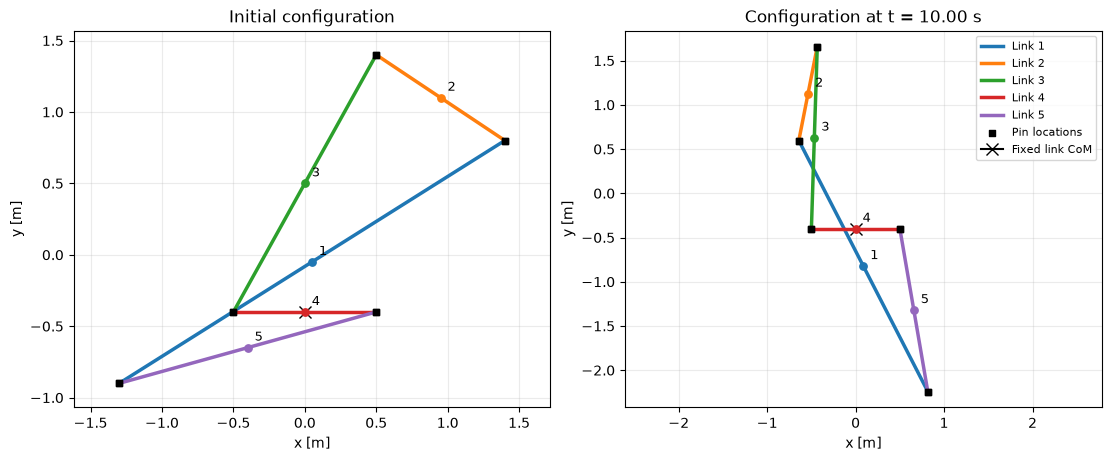

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
draw_configuration(axes[0], q0, 'Initial configuration')
draw_configuration(axes[1], q_final, f'Configuration at t = {solution.t[-1]:.2f} s')
axes[1].legend(loc='best', fontsize=8)
plt.show()

In [42]:
from pathlib import Path

figure_directory = Path.cwd() / 'figures'
figure_directory.mkdir(parents=True, exist_ok=True)
configuration_figure_path = figure_directory / 'five_link_configurations.png'
fig.savefig(configuration_figure_path, dpi=180, bbox_inches='tight')
print(f'Saved configuration figure: {configuration_figure_path.resolve()}')

Saved configuration figure: C:\Users\Mourad\Desktop\multybody systems\figures\five_link_configurations.png


In [43]:
from pathlib import Path
from matplotlib.animation import FuncAnimation, PillowWriter
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, display

fps = 20
movie_duration = float(solution.t[-1])
frame_count = int(round(movie_duration * fps))
coordinate_count = 3 * body_count

# Each frame displays for 1/fps seconds. Match labels to playback time and omit t=end,
# which is the boundary after the final frame rather than a frame's display time.
frame_times = np.arange(frame_count, dtype=float) / fps
frame_indices = np.array([
    np.argmin(np.abs(solution.t - frame_time))
    for frame_time in frame_times
])
assert np.allclose(solution.t[frame_indices], frame_times, atol=1e-12, rtol=0.0)

center_history = np.stack([
    solution.y[3 * body:3 * body + 2, :].T for body in range(body_count)
])


def joint_positions_at(q):
    points = []
    for body_a, body_b, local_a, local_b in system.joints:
        if body_a == -1:
            body = body_b
            local_point = local_b
        else:
            body = body_a
            local_point = local_a
        start = 3 * body
        points.append(q[start:start + 2] + system.point_offset(q, body, local_point))
    return np.asarray(points)


# Precompute pins and CoMs across the trajectory so the animation axes stay fixed.
pin_history = np.asarray([
    joint_positions_at(solution.y[:coordinate_count, index])
    for index in range(solution.t.size)
])
all_positions = np.concatenate((center_history.reshape(-1, 2), pin_history.reshape(-1, 2)))
margin = 0.5
x_limits = (all_positions[:, 0].min() - margin, all_positions[:, 0].max() + margin)
y_limits = (all_positions[:, 1].min() - margin, all_positions[:, 1].max() + margin)

### Animation setup and frame sampling

The ODE solver stores 2,001 output states over the ten-second interval. We select 200 evenly spaced state indices for a 20-frame-per-second movie. The movie is a visualization of the computed trajectory: it does not participate in or change the dynamics calculation. The axis limits are computed across the entire trajectory so moving links remain in frame.

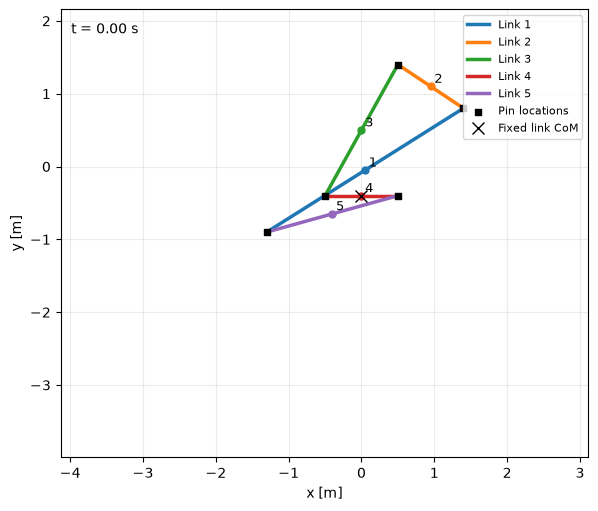

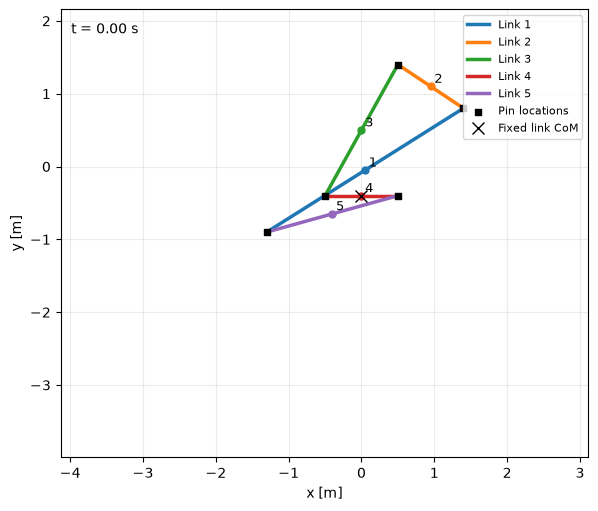

In [44]:
movie_fig, movie_ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
body_lines = []
center_markers = []
body_labels = []
for body in range(body_count):
    line, = movie_ax.plot([], [], color=f'C{body}', linewidth=2.5, label=f'Link {body + 1}')
    marker, = movie_ax.plot([], [], marker='o', linestyle='None', color=f'C{body}', markersize=5)
    body_lines.append(line)
    center_markers.append(marker)
    body_labels.append(movie_ax.text(0.0, 0.0, str(body + 1), fontsize=9))
pin_marker = movie_ax.scatter([], [], marker='s', color='black', s=22, label='Pin locations', zorder=4)
time_label = movie_ax.text(0.02, 0.97, '', transform=movie_ax.transAxes, va='top')
fixed_marker, = movie_ax.plot([], [], marker='x', linestyle='None', color='black',
                              markersize=9, label='Fixed link CoM')
movie_ax.set_xlim(*x_limits)
movie_ax.set_ylim(*y_limits)
movie_ax.set_aspect('equal', adjustable='box')
movie_ax.set_xlabel('x [m]')
movie_ax.set_ylabel('y [m]')
movie_ax.grid(True, alpha=0.25)
movie_ax.legend(loc='upper right', fontsize=8)


def update_movie(frame_number):
    sample_index = frame_indices[frame_number]
    q = solution.y[:coordinate_count, sample_index]
    pose = q.reshape(body_count, 3)
    for body in range(body_count):
        center = pose[body, :2]
        points = body_attachment_points(system, q, body)
        order = np.argsort(np.arctan2(points[:, 1] - center[1], points[:, 0] - center[0]))
        outline = points[order]
        if len(outline) > 2:
            outline = np.vstack((outline, outline[0]))

        # Update existing Matplotlib artists instead of rebuilding the plot each frame.
        body_lines[body].set_data(outline[:, 0], outline[:, 1])
        center_markers[body].set_data([center[0]], [center[1]])
        body_labels[body].set_position((center[0] + 0.05, center[1] + 0.05))
    pin_marker.set_offsets(joint_positions_at(q))
    fixed_marker.set_data([q[9]], [q[10]])
    time_label.set_text(f't = {solution.t[sample_index]:.2f} s')
    return (*body_lines, *center_markers, *body_labels, pin_marker, fixed_marker, time_label)


# Draw frame zero for a useful preview before writing the animation file.
update_movie(0)
display(movie_fig)

### Write and verify the movie

At 20 fps, a ten-second GIF needs 200 frames. Each frame uses one saved solution state. The final checks reopen the file and inspect its encoded frame count and total frame duration instead of assuming that a successful `save` call means the requested duration was written.

Saved: C:\Users\Mourad\Desktop\multybody systems\constrained_five_link_10s.gif
Duration: 10.00 s | Frames: 200 | FPS: 20 | Size: 1,246,638 bytes


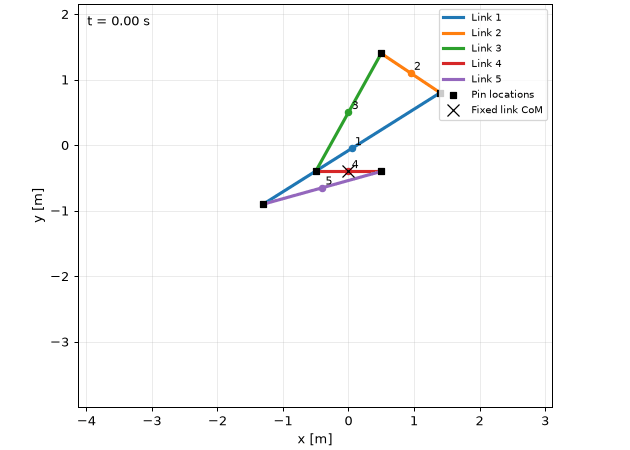

In [45]:
# FuncAnimation calls update_movie for each sampled trajectory state.
movie = FuncAnimation(
    movie_fig,
    update_movie,
    frames=frame_count,
    interval=1000 / fps,
    repeat=False,
    blit=False,
)
movie_path = Path.cwd() / 'constrained_five_link_10s.gif'

# PillowWriter encodes the requested frame rate into the animated GIF.
movie.save(movie_path, writer=PillowWriter(fps=fps), dpi=90)
plt.close(movie_fig)

# Reopen the artifact and verify its actual encoded duration and number of frames.
with PILImage.open(movie_path) as saved_movie:
    saved_frames = saved_movie.n_frames
    duration_ms = sum(
        saved_movie.seek(index) or saved_movie.info.get('duration', 0)
        for index in range(saved_frames)
    )
assert saved_frames == frame_count
assert duration_ms == int(movie_duration * 1000)
print(f'Saved: {movie_path.resolve()}')
print(f'Duration: {duration_ms / 1000:.2f} s | Frames: {saved_frames} | FPS: {fps} | Size: {movie_path.stat().st_size:,} bytes')
display(NotebookImage(filename=str(movie_path)))

## Symbolic inverse dynamics for the P34 motor

Let `tau_34` be positive on link 3 and negative on link 4. Its generalized-force vector is `B_34*tau_34`, with nonzero entries in the `theta_3` and `theta_4` rows. The controlled output is the motor-relative angle `y_34 = theta_3 - theta_4`; its output Jacobian is `J_34 = dy_34/dq`, with `+1` in the `theta_3` column and `-1` in the `theta_4` column. For this linear angular output, `J_34` is constant and its acceleration bias `Jdot_34*qdot` is zero.

Since the mechanism has two degrees of freedom but one motor, prescribe one output acceleration rather than all 15 Cartesian accelerations. Let the commanded motor-relative angular acceleration be `alpha_34`:

$$
M\ddot q + J^T\lambda = Q_g + B_{34}\tau_{34},
\qquad J\ddot q + \dot J\dot q = 0,
\qquad J_{34}\ddot q + \dot J_{34}\dot q = \alpha_{34}.
$$

The unknowns are all 15 components of `qddot`, 13 ideal constraint reactions `lambda`, and the motor torque `tau_34`. The symbolic inverse-dynamics system is

$$
\begin{bmatrix}
M & J^T & -B_{34} \\
J & 0 & 0 \\
J_{34} & 0 & 0
\end{bmatrix}
\begin{bmatrix} \ddot q \\ \lambda \\ \tau_{34} \end{bmatrix}
=
\begin{bmatrix} Q_g \\ -\dot J\dot q \\ \alpha_{34} \end{bmatrix}.
$$

This is a 29-equation system for 29 unknowns. If it is nonsingular at the pose, the commanded motor-coordinate acceleration determines the motor torque, the reactions, and the remaining free-coordinate acceleration together. The other degree of freedom is not assigned an arbitrary acceleration; its motion follows from the dynamics. This instantaneous inverse-dynamics solve is not by itself a trajectory-tracking controller.

The sign convention can also be checked by power: `qdot.T @ (B_34*tau_34)` equals `tau_34*(theta_dot_3-theta_dot_4)`, the motor torque times the relative angular speed across P34.

In [46]:
tau_34_sym, alpha_34_sym = sp.symbols('tau_34 alpha_34', real=True)
relative_angle_P34_sym = q_sym[3 * link_3 + 2] - q_sym[3 * link_4 + 2]
relative_angle_jacobian_P34_sym = sp.Matrix([relative_angle_P34_sym]).jacobian(q_sym)
relative_angle_bias_P34_sym = sp.simplify(
    (relative_angle_jacobian_P34_sym * qdot_sym).jacobian(q_sym) * qdot_sym
)

actuator_map_P34_sym = sp.zeros(3 * body_count, 1)
actuator_map_P34_sym[3 * link_3 + 2] = 1
actuator_map_P34_sym[3 * link_4 + 2] = -1

assert relative_angle_jacobian_P34_sym.shape == (1, 15)
assert relative_angle_jacobian_P34_sym[0, 3 * link_3 + 2] == 1
assert relative_angle_jacobian_P34_sym[0, 3 * link_4 + 2] == -1
assert relative_angle_bias_P34_sym == sp.zeros(1, 1)
assert actuator_map_P34_sym == relative_angle_jacobian_P34_sym.T

display(Markdown('**P34 output Jacobian** $J_{34}=\\partial(\\theta_3-\\theta_4)/\\partial q$:'))
display(relative_angle_jacobian_P34_sym)
display(Markdown('**Generalized-force direction** $B_{34}=J_{34}^T$:'))
display(actuator_map_P34_sym)

**P34 output Jacobian** $J_{34}=\partial(\theta_3-\theta_4)/\partial q$:

Matrix([[0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, -1, 0, 0, 0]])

**Generalized-force direction** $B_{34}=J_{34}^T$:

Matrix([
[ 0],
[ 0],
[ 0],
[ 0],
[ 0],
[ 0],
[ 0],
[ 0],
[ 1],
[ 0],
[ 0],
[-1],
[ 0],
[ 0],
[ 0]])

### Form the actuated force balance

Subtract applied gravity and motor generalized force from the inertial and constraint-force terms. This produces the 15 equations that the inverse solver must satisfy.

In [47]:
dynamic_residual_P34_sym = (
    mass_sym * qddot_sym
    + jac_sym.T * lambda_sym
    - generalized_force_sym
    - actuator_map_P34_sym * tau_34_sym
)
motor_power_P34_sym = sp.expand(
    (qdot_sym.T * actuator_map_P34_sym)[0] * tau_34_sym
)

assert dynamic_residual_P34_sym.shape == (15, 1)
assert sp.simplify(
    motor_power_P34_sym - tau_34_sym * (qdot_symbols[8] - qdot_symbols[11])
) == 0

display(Markdown('**Actuated generalized-force balance residual:**'))
display(dynamic_residual_P34_sym)
display(Markdown('**Motor power** $P_{34}=\\tau_{34}\\dot y_{34}$:'))
display(sp.Eq(sp.Symbol('P_34'), motor_power_P34_sym))

**Actuated generalized-force balance residual:**

Matrix([
[                                                                                                                   lambda_1 - lambda_9 + m1*x_ddot1],
[                                                                                                           g*m1 - lambda_10 + lambda_2 + m1*y_ddot1],
[                    I1*theta_ddot1 - L1*lambda_1*sin(theta1)/2 + L1*lambda_10*cos(theta1)/2 + L1*lambda_2*cos(theta1)/2 - L1*lambda_9*sin(theta1)/2],
[                                                                                                                  -lambda_1 + lambda_3 + m2*x_ddot2],
[                                                                                                            g*m2 - lambda_2 + lambda_4 + m2*y_ddot2],
[                     I2*theta_ddot2 - L2*lambda_1*sin(theta2)/2 + L2*lambda_2*cos(theta2)/2 - L2*lambda_3*sin(theta2)/2 + L2*lambda_4*cos(theta2)/2],
[                                                                                    

**Motor power** $P_{34}=\tau_{34}\dot y_{34}$:

Eq(P_34, tau_34*theta_dot3 - tau_34*theta_dot4)

### Assemble the inverse-dynamics system

The unknown vector contains 15 accelerations, 13 constraint reactions, and the unknown motor torque. The final row prescribes the relative angular acceleration through the output Jacobian.

In [48]:
inverse_unknown_P34_sym = qddot_sym.col_join(lambda_sym).col_join(sp.Matrix([tau_34_sym]))
inverse_rhs_P34_sym = (
    generalized_force_sym
    .col_join(-jdot_qdot_sym)
    .col_join(sp.Matrix([alpha_34_sym - relative_angle_bias_P34_sym[0]]))
)
inverse_matrix_P34_sym = sp.BlockMatrix([
    [mass_sym, jac_sym.T, -actuator_map_P34_sym],
    [jac_sym, sp.zeros(system.n_constraints, system.n_constraints), sp.zeros(system.n_constraints, 1)],
    [relative_angle_jacobian_P34_sym, sp.zeros(1, system.n_constraints), sp.zeros(1, 1)],
]).as_explicit()
inverse_system_residual_P34_sym = (
    inverse_matrix_P34_sym * inverse_unknown_P34_sym
    - inverse_rhs_P34_sym
)

assert inverse_matrix_P34_sym.shape == (29, 29)
assert inverse_unknown_P34_sym.shape == (29, 1)
assert inverse_rhs_P34_sym.shape == (29, 1)

display(Markdown('**Augmented inverse-dynamics linear system** $K_{34}z_{34}=b_{34}$:'))
display(sp.Eq(
    sp.MatrixSymbol('K_P34', 29, 29) * sp.MatrixSymbol('z_P34', 29, 1),
    inverse_rhs_P34_sym,
))

**Augmented inverse-dynamics linear system** $K_{34}z_{34}=b_{34}$:

Eq(K_P34*z_P34, Matrix([
[                                                              0],
[                                                          -g*m1],
[                                                              0],
[                                                              0],
[                                                          -g*m2],
[                                                              0],
[                                                              0],
[                                                          -g*m3],
[                                                              0],
[                                                              0],
[                                                          -g*m4],
[                                                              0],
[                                                              0],
[                                                          -g*m5],
[                                    

### Verify the symbolic blocks

Check that each block of the assembled system matches its defining equation: force balance, ideal acceleration constraints, and prescribed output acceleration. Also verify that actuator power has the expected sign.

In [49]:
assert inverse_system_residual_P34_sym[:15, :] == dynamic_residual_P34_sym
assert inverse_system_residual_P34_sym[15:28, :] == ideal_acceleration_constraint_sym
assert inverse_system_residual_P34_sym[28, 0] == (
    relative_angle_jacobian_P34_sym * qddot_sym
)[0] - alpha_34_sym

print('Symbolic inverse dynamics: 29 equations for 15 accelerations, 13 reactions, and one unknown P34 torque.')
print('The output Jacobian and actuator map are transposes; relative-angle acceleration bias is zero.')
display(Markdown('**Ideal acceleration constraints:**'))
display(ideal_acceleration_constraint_sym)
display(Markdown('**Prescribed P34 relative angular acceleration:**'))
display(sp.Eq(
    (relative_angle_jacobian_P34_sym * qddot_sym)[0],
    alpha_34_sym,
))

Symbolic inverse dynamics: 29 equations for 15 accelerations, 13 reactions, and one unknown P34 torque.
The output Jacobian and actuator map are transposes; relative-angle acceleration bias is zero.


**Ideal acceleration constraints:**

Matrix([
[-L1*theta_ddot1*sin(theta1)/2 - L1*theta_dot1**2*cos(theta1)/2 - L2*theta_ddot2*sin(theta2)/2 - L2*theta_dot2**2*cos(theta2)/2 + x_ddot1 - x_ddot2],
[ L1*theta_ddot1*cos(theta1)/2 - L1*theta_dot1**2*sin(theta1)/2 + L2*theta_ddot2*cos(theta2)/2 - L2*theta_dot2**2*sin(theta2)/2 + y_ddot1 - y_ddot2],
[-L2*theta_ddot2*sin(theta2)/2 - L2*theta_dot2**2*cos(theta2)/2 - L3*theta_ddot3*sin(theta3)/2 - L3*theta_dot3**2*cos(theta3)/2 + x_ddot2 - x_ddot3],
[ L2*theta_ddot2*cos(theta2)/2 - L2*theta_dot2**2*sin(theta2)/2 + L3*theta_ddot3*cos(theta3)/2 - L3*theta_dot3**2*sin(theta3)/2 + y_ddot2 - y_ddot3],
[-L3*theta_ddot3*sin(theta3)/2 - L3*theta_dot3**2*cos(theta3)/2 - L4*theta_ddot4*sin(theta4)/2 - L4*theta_dot4**2*cos(theta4)/2 + x_ddot3 - x_ddot4],
[ L3*theta_ddot3*cos(theta3)/2 - L3*theta_dot3**2*sin(theta3)/2 + L4*theta_ddot4*cos(theta4)/2 - L4*theta_dot4**2*sin(theta4)/2 + y_ddot3 - y_ddot4],
[-L4*theta_ddot4*sin(theta4)/2 - L4*theta_dot4**2*cos(theta4)/2 - L5*theta_ddot5*sin(theta5

**Prescribed P34 relative angular acceleration:**

Eq(theta_ddot3 - theta_ddot4, alpha_34)

## Numerical inverse-dynamics solve

At the projected initial state, prescribe a relative angular acceleration of `0.5 rad/s^2` across P34. The 29-by-29 augmented system solves simultaneously for all generalized accelerations, the 13 constraint reactions, and the unknown motor torque. This is a direct inverse-dynamics calculation, not a forward-generated torque round trip; it is an instantaneous result and does not yet demonstrate tracking over a trajectory.

In [50]:
# One actuator: positive P34 torque acts on link 3 and oppositely on link 4.
actuator_map_P34 = np.zeros(3 * body_count)
actuator_map_P34[3 * link_3 + 2] = 1.0
actuator_map_P34[3 * link_4 + 2] = -1.0

# The actuator output is the relative pin angle theta_3 - theta_4.
target_relative_angular_acceleration_rad_s2 = 0.5
phi_inverse, jac_inverse = system.constraints_and_jacobian(q0)
gamma_inverse = system.jdot_qdot(q0, qdot0)
relative_angle_jacobian_P34 = np.zeros((1, 3 * body_count))
relative_angle_jacobian_P34[0, 3 * link_3 + 2] = 1.0
relative_angle_jacobian_P34[0, 3 * link_4 + 2] = -1.0
relative_angle_bias_P34 = 0.0

constraint_count = system.n_constraints
coordinate_count = 3 * body_count
inverse_kkt_P34 = np.block([
    [
        system.mass_matrix,
        jac_inverse.T,
        -actuator_map_P34[:, np.newaxis],
    ],
    [
        jac_inverse,
        np.zeros((constraint_count, constraint_count)),
        np.zeros((constraint_count, 1)),
    ],
    [
        relative_angle_jacobian_P34,
        np.zeros((1, constraint_count)),
        np.zeros((1, 1)),
    ],
])
inverse_rhs_P34 = np.concatenate((
    system.generalized_forces(q0, qdot0, 0.0),
    -gamma_inverse,
    [target_relative_angular_acceleration_rad_s2 - relative_angle_bias_P34],
))
inverse_rank_P34 = np.linalg.matrix_rank(inverse_kkt_P34)
assert inverse_kkt_P34.shape == (29, 29)
assert inverse_rank_P34 == 29
assert relative_angle_jacobian_P34[0, 3 * link_3 + 2] == 1.0
assert relative_angle_jacobian_P34[0, 3 * link_4 + 2] == -1.0

inverse_solution_P34 = np.linalg.solve(inverse_kkt_P34, inverse_rhs_P34)
qdd_inverse_P34 = inverse_solution_P34[:coordinate_count]
lambda_inverse_P34 = inverse_solution_P34[coordinate_count:coordinate_count + constraint_count]
solved_torque_P34_N_m = inverse_solution_P34[-1]

force_balance_residual_P34 = (
    system.mass_matrix @ qdd_inverse_P34
    + jac_inverse.T @ lambda_inverse_P34
    - system.generalized_forces(q0, qdot0, 0.0)
    - actuator_map_P34 * solved_torque_P34_N_m
)
force_balance_by_body_P34 = force_balance_residual_P34.reshape(body_count, 3)
force_residual_P34_N = np.linalg.norm(force_balance_by_body_P34[:, :2], ord=np.inf)
moment_residual_P34_N_m = np.linalg.norm(force_balance_by_body_P34[:, 2], ord=np.inf)
acceleration_constraint_residual_P34 = jac_inverse @ qdd_inverse_P34 + gamma_inverse
relative_acceleration_residual_P34 = (
    (relative_angle_jacobian_P34 @ qdd_inverse_P34)[0]
    + relative_angle_bias_P34
    - target_relative_angular_acceleration_rad_s2
)

assert force_residual_P34_N < 1e-9
assert moment_residual_P34_N_m < 1e-9
assert np.linalg.norm(acceleration_constraint_residual_P34, ord=np.inf) < 1e-9
assert abs(relative_acceleration_residual_P34) < 1e-10

print('Inverse dynamics solved with the P34 torque as an unknown.')
print(f'Prescribed relative angular acceleration: {target_relative_angular_acceleration_rad_s2:.6f} rad/s^2')
print(f'Solved P34 motor torque: {solved_torque_P34_N_m:.9f} N m')
print(f'Augmented inverse-system rank: {inverse_rank_P34}/29')
print(f'Max force-balance residual: {force_residual_P34_N:.3e} N')
print(f'Max moment-balance residual: {moment_residual_P34_N_m:.3e} N m')
print(f'Max ideal acceleration-constraint residual: {np.linalg.norm(acceleration_constraint_residual_P34, ord=np.inf):.3e}')
print(f'Relative angular-acceleration command residual: {relative_acceleration_residual_P34:.3e} rad/s^2')

Inverse dynamics solved with the P34 torque as an unknown.
Prescribed relative angular acceleration: 0.500000 rad/s^2
Solved P34 motor torque: 20.004112269 N m
Augmented inverse-system rank: 29/29
Max force-balance residual: 5.995e-15 N
Max moment-balance residual: 3.553e-15 N m
Max ideal acceleration-constraint residual: 8.295e-15
Relative angular-acceleration command residual: 0.000e+00 rad/s^2


## Inverse-dynamics torque history

Now command a smooth relative angular acceleration over one four-second cycle. At every state, solve the augmented inverse-dynamics equations using the constraint Jacobian `J` and the P34 output Jacobian `J_34`; store the resulting motor torque. Baumgarte feedback is used only in the numerical constraint rows to limit integration drift. The saved torque history will then be interpolated and injected into a separate forward-dynamics solve.

Inverse-driven rollout: 4.00 s, 6518 RHS evaluations
Inverse torque samples: 6401 (1600 per second)
P34 torque range: -91.885449 to 28.686897 N m
Max commanded-acceleration residual: 3.256e-14 rad/s^2
Augmented inverse-system rank across samples: 29..29


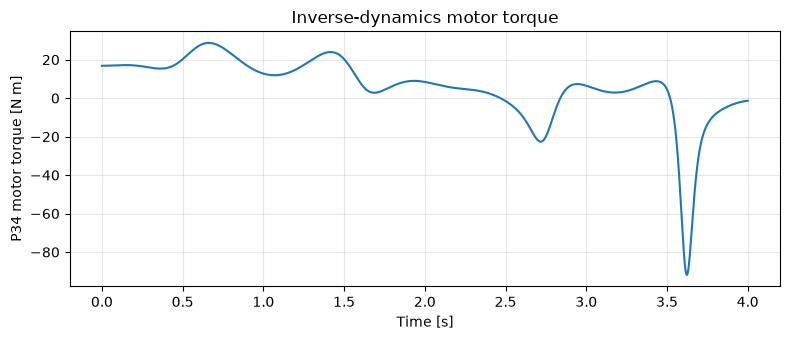

In [51]:
driven_duration = 4.0
driven_frame_rate = 20
driven_samples_per_second = 1600
driven_sample_count = int(round(driven_duration * driven_samples_per_second)) + 1
driven_sample_times = np.linspace(0.0, driven_duration, driven_sample_count)
command_amplitude_rad_s2 = 0.2
command_frequency_rad_s = 2.0 * np.pi / driven_duration
inverse_baumgarte_zeta = 1.0
inverse_baumgarte_omega_rad_s = 20.0

def commanded_relative_angular_acceleration(time):
    return command_amplitude_rad_s2 * np.sin(command_frequency_rad_s * time)


def solve_P34_inverse_dynamics(time, q, qdot):
    phi, jac = system.constraints_and_jacobian(q)
    phi_dot = jac @ qdot
    gamma = system.jdot_qdot(q, qdot)
    stabilized_constraint_rhs = (
        -gamma
        - 2.0 * inverse_baumgarte_zeta * inverse_baumgarte_omega_rad_s * phi_dot
        - inverse_baumgarte_omega_rad_s**2 * phi
    )
    inverse_matrix = np.block([
        [system.mass_matrix, jac.T, -actuator_map_P34[:, np.newaxis]],
        [jac, np.zeros((constraint_count, constraint_count)), np.zeros((constraint_count, 1))],
        [relative_angle_jacobian_P34, np.zeros((1, constraint_count)), np.zeros((1, 1))],
    ])
    inverse_rhs = np.concatenate((
        system.generalized_forces(q, qdot, time),
        stabilized_constraint_rhs,
        [commanded_relative_angular_acceleration(time)],
    ))
    solution = np.linalg.solve(inverse_matrix, inverse_rhs)
    return solution[:coordinate_count], solution[coordinate_count:coordinate_count + constraint_count], solution[-1]


def inverse_controlled_state_derivative(time, state):
    q = state[:coordinate_count]
    qdot = state[coordinate_count:]
    qddot, _, _ = solve_P34_inverse_dynamics(time, q, qdot)
    return np.concatenate((qdot, qddot))

inverse_driven_solution = solve_ivp(
    inverse_controlled_state_derivative,
    (0.0, driven_duration),
    state0,
    t_eval=driven_sample_times,
    rtol=1e-9,
    atol=1e-11,
    max_step=0.01,
)
if not inverse_driven_solution.success:
    raise RuntimeError(inverse_driven_solution.message)

inverse_driven_q = inverse_driven_solution.y[:coordinate_count, :]
inverse_driven_qdot = inverse_driven_solution.y[coordinate_count:, :]
inverse_torque_history_N_m = np.empty(inverse_driven_solution.t.size)
inverse_command_residual_history = np.empty(inverse_driven_solution.t.size)
inverse_matrix_ranks = np.empty(inverse_driven_solution.t.size, dtype=int)
for sample_index, sample_time in enumerate(inverse_driven_solution.t):
    sample_q = inverse_driven_q[:, sample_index]
    sample_qdot = inverse_driven_qdot[:, sample_index]
    sample_qddot, _, sample_torque = solve_P34_inverse_dynamics(
        sample_time, sample_q, sample_qdot
    )
    inverse_torque_history_N_m[sample_index] = sample_torque
    inverse_command_residual_history[sample_index] = (
        (relative_angle_jacobian_P34 @ sample_qddot)[0]
        - commanded_relative_angular_acceleration(sample_time)
    )
    _, sample_jac = system.constraints_and_jacobian(sample_q)
    sample_stabilized_kkt = np.block([
        [system.mass_matrix, sample_jac.T, -actuator_map_P34[:, np.newaxis]],
        [sample_jac, np.zeros((constraint_count, constraint_count)), np.zeros((constraint_count, 1))],
        [relative_angle_jacobian_P34, np.zeros((1, constraint_count)), np.zeros((1, 1))],
    ])
    inverse_matrix_ranks[sample_index] = np.linalg.matrix_rank(sample_stabilized_kkt)

assert np.all(inverse_matrix_ranks == 29)
assert np.max(np.abs(inverse_command_residual_history)) < 1e-9
assert np.all(np.isfinite(inverse_torque_history_N_m))
print(f'Inverse-driven rollout: {inverse_driven_solution.t[-1]:.2f} s, {inverse_driven_solution.nfev} RHS evaluations')
print(f'Inverse torque samples: {inverse_driven_solution.t.size} ({driven_samples_per_second} per second)')
print(f'P34 torque range: {inverse_torque_history_N_m.min():.6f} to {inverse_torque_history_N_m.max():.6f} N m')
print(f'Max commanded-acceleration residual: {np.max(np.abs(inverse_command_residual_history)):.3e} rad/s^2')
print(f'Augmented inverse-system rank across samples: {inverse_matrix_ranks.min()}..{inverse_matrix_ranks.max()}')
plt.figure(figsize=(8, 3.5))
plt.plot(inverse_driven_solution.t, inverse_torque_history_N_m)
plt.xlabel('Time [s]')
plt.ylabel('P34 motor torque [N m]')
plt.title('Inverse-dynamics motor torque')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Constraint and conditioning diagnostics

Check that the inverse-driven motion remains on the five pin and grounded-link constraints, and inspect the configuration where the required motor effort is largest. Full matrix rank is necessary but does not by itself rule out poor conditioning.

In [52]:
driven_pin_position_error_m = []
driven_ground_translation_error_m = []
driven_ground_angle_error_rad = []
driven_pin_velocity_error_m_s = []
driven_ground_translation_rate_m_s = []
driven_ground_angular_rate_rad_s = []
for sample_index in range(inverse_driven_solution.t.size):
    sample_q = inverse_driven_q[:, sample_index]
    sample_qdot = inverse_driven_qdot[:, sample_index]
    sample_phi, sample_jac = system.constraints_and_jacobian(sample_q)
    sample_velocity_residual = sample_jac @ sample_qdot
    driven_pin_position_error_m.append(np.linalg.norm(sample_phi[:10], ord=np.inf))
    driven_ground_translation_error_m.append(np.linalg.norm(sample_phi[10:12], ord=np.inf))
    driven_ground_angle_error_rad.append(np.linalg.norm(sample_phi[12:]))
    driven_pin_velocity_error_m_s.append(np.linalg.norm(sample_velocity_residual[:10], ord=np.inf))
    driven_ground_translation_rate_m_s.append(np.linalg.norm(sample_velocity_residual[10:12], ord=np.inf))
    driven_ground_angular_rate_rad_s.append(np.linalg.norm(sample_velocity_residual[12:]))

max_driven_pin_position_error_m = max(driven_pin_position_error_m)
max_driven_ground_translation_error_m = max(driven_ground_translation_error_m)
max_driven_ground_angle_error_rad = max(driven_ground_angle_error_rad)
max_driven_pin_velocity_error_m_s = max(driven_pin_velocity_error_m_s)
max_driven_ground_translation_rate_m_s = max(driven_ground_translation_rate_m_s)
max_driven_ground_angular_rate_rad_s = max(driven_ground_angular_rate_rad_s)
torque_peak_index = int(np.argmax(np.abs(inverse_torque_history_N_m)))
torque_peak_time_s = inverse_driven_solution.t[torque_peak_index]
torque_peak_q = inverse_driven_q[:, torque_peak_index]
_, torque_peak_jacobian = system.constraints_and_jacobian(torque_peak_q)
peak_jacobian_singular_values = np.linalg.svd(torque_peak_jacobian, compute_uv=False)
peak_constraint_jacobian_condition = peak_jacobian_singular_values[0] / peak_jacobian_singular_values[-1]
peak_inverse_matrix = np.block([
    [system.mass_matrix, torque_peak_jacobian.T, -actuator_map_P34[:, np.newaxis]],
    [torque_peak_jacobian, np.zeros((constraint_count, constraint_count)), np.zeros((constraint_count, 1))],
    [relative_angle_jacobian_P34, np.zeros((1, constraint_count)), np.zeros((1, 1))],
])
peak_inverse_condition = np.linalg.cond(peak_inverse_matrix)

print(f'Max pin closure error: {max_driven_pin_position_error_m:.3e} m')
print(f'Max grounded translation error: {max_driven_ground_translation_error_m:.3e} m')
print(f'Max grounded angle error: {max_driven_ground_angle_error_rad:.3e} rad')
print(f'Max pin velocity residual: {max_driven_pin_velocity_error_m_s:.3e} m/s')
print(f'Max grounded translation rate: {max_driven_ground_translation_rate_m_s:.3e} m/s')
print(f'Max grounded angular rate: {max_driven_ground_angular_rate_rad_s:.3e} rad/s')
print(f'Peak absolute P34 torque: {inverse_torque_history_N_m[torque_peak_index]:.6f} N m at t={torque_peak_time_s:.3f} s')
print(f'Constraint Jacobian condition at torque peak: {peak_constraint_jacobian_condition:.3e}')
print(f'Augmented inverse matrix condition at torque peak: {peak_inverse_condition:.3e}')

Max pin closure error: 4.072e-11 m
Max grounded translation error: 3.804e-18 m
Max grounded angle error: 3.031e-19 rad
Max pin velocity residual: 1.105e-09 m/s
Max grounded translation rate: 1.332e-16 m/s
Max grounded angular rate: 1.648e-17 rad/s
Peak absolute P34 torque: -91.885449 N m at t=3.623 s
Constraint Jacobian condition at torque peak: 1.369e+01
Augmented inverse matrix condition at torque peak: 1.332e+02


## Forward replay using the solved torque history

Use the sampled inverse-dynamics torque as the actuator input to the original forward constrained equations. The state starts from the same projected initial conditions; the forward model computes accelerations and reactions from `Q_g + B_34*tau_34(t)`. The torque trace is sampled at 1600 Hz and interpolated with a natural cubic spline; solver tolerances and Baumgarte gains are held fixed between inverse and forward passes.

The replay diagnostics separate two effects: pin and ground residuals measure constraint closure, while the maximum coordinate difference measures how closely the forward run reproduces the inverse-driven trajectory. The latter is sensitive to torque interpolation and should not be mistaken for constraint violation.

In [53]:
from scipy.interpolate import CubicSpline

torque_history_interpolator_P34 = CubicSpline(
    driven_sample_times,
    inverse_torque_history_N_m,
    bc_type='natural',
)


def solve_P34_forward_dynamics(time, q, qdot):
    phi, jac = system.constraints_and_jacobian(q)
    phi_dot = jac @ qdot
    constraint_rhs = (
        -system.jdot_qdot(q, qdot)
        - 2.0 * inverse_baumgarte_zeta * inverse_baumgarte_omega_rad_s * phi_dot
        - inverse_baumgarte_omega_rad_s**2 * phi
    )
    applied_torque = float(torque_history_interpolator_P34(time))
    kkt = np.block([
        [system.mass_matrix, jac.T],
        [jac, np.zeros((constraint_count, constraint_count))],
    ])
    rhs = np.concatenate((
        system.generalized_forces(q, qdot, time) + actuator_map_P34 * applied_torque,
        constraint_rhs,
    ))
    solution = np.linalg.solve(kkt, rhs)
    return solution[:coordinate_count], applied_torque


def P34_forward_replay_state_derivative(time, state):
    q = state[:coordinate_count]
    qdot = state[coordinate_count:]
    qddot, _ = solve_P34_forward_dynamics(time, q, qdot)
    return np.concatenate((qdot, qddot))

forward_replay_solution = solve_ivp(
    P34_forward_replay_state_derivative,
    (0.0, driven_duration),
    state0,
    t_eval=driven_sample_times,
    rtol=1e-10,
    atol=1e-12,
    max_step=0.0025,
)
if not forward_replay_solution.success:
    raise RuntimeError(forward_replay_solution.message)

forward_replay_q = forward_replay_solution.y[:coordinate_count, :]
forward_replay_qdot = forward_replay_solution.y[coordinate_count:, :]
forward_replay_max_coordinate_difference = np.max(
    np.abs(forward_replay_q - inverse_driven_q)
)
replay_pin_position_errors_m = []
replay_ground_translation_errors_m = []
replay_ground_angle_errors_rad = []
replay_pin_velocity_errors_m_s = []
replay_ground_translation_rates_m_s = []
replay_ground_angular_rates_rad_s = []
for sample_index in range(forward_replay_solution.t.size):
    sample_q = forward_replay_q[:, sample_index]
    sample_qdot = forward_replay_qdot[:, sample_index]
    sample_phi, sample_jac = system.constraints_and_jacobian(sample_q)
    sample_velocity_residual = sample_jac @ sample_qdot
    replay_pin_position_errors_m.append(np.linalg.norm(sample_phi[:10], ord=np.inf))
    replay_ground_translation_errors_m.append(np.linalg.norm(sample_phi[10:12], ord=np.inf))
    replay_ground_angle_errors_rad.append(np.linalg.norm(sample_phi[12:]))
    replay_pin_velocity_errors_m_s.append(np.linalg.norm(sample_velocity_residual[:10], ord=np.inf))
    replay_ground_translation_rates_m_s.append(np.linalg.norm(sample_velocity_residual[10:12], ord=np.inf))
    replay_ground_angular_rates_rad_s.append(np.linalg.norm(sample_velocity_residual[12:]))

max_replay_pin_position_error_m = max(replay_pin_position_errors_m)
max_replay_ground_translation_error_m = max(replay_ground_translation_errors_m)
max_replay_ground_angle_error_rad = max(replay_ground_angle_errors_rad)
max_replay_pin_velocity_error_m_s = max(replay_pin_velocity_errors_m_s)
max_replay_ground_translation_rate_m_s = max(replay_ground_translation_rates_m_s)
max_replay_ground_angular_rate_rad_s = max(replay_ground_angular_rates_rad_s)
assert max_replay_pin_position_error_m < 1e-8
assert max_replay_ground_translation_error_m < 1e-10
assert max_replay_ground_angle_error_rad < 1e-10
assert max_replay_pin_velocity_error_m_s < 1e-6
assert max_replay_ground_translation_rate_m_s < 1e-8
assert max_replay_ground_angular_rate_rad_s < 1e-8
assert forward_replay_max_coordinate_difference < 2e-3
print(f'Forward replay: success={forward_replay_solution.success}, nfev={forward_replay_solution.nfev}')
print(f'Max absolute coordinate difference vs inverse rollout: {forward_replay_max_coordinate_difference:.3e}')
print(f'Max replay pin closure error: {max_replay_pin_position_error_m:.3e} m')
print(f'Max replay grounded translation error: {max_replay_ground_translation_error_m:.3e} m')
print(f'Max replay grounded angle error: {max_replay_ground_angle_error_rad:.3e} rad')
print(f'Max replay pin velocity residual: {max_replay_pin_velocity_error_m_s:.3e} m/s')

Forward replay: success=True, nfev=11048
Max absolute coordinate difference vs inverse rollout: 7.958e-07
Max replay pin closure error: 3.732e-12 m
Max replay grounded translation error: 2.418e-18 m
Max replay grounded angle error: 3.031e-19 rad
Max replay pin velocity residual: 1.017e-10 m/s


## Animate the forward replay

Render the torque-reinjected forward solution, not the inverse pass. Frame times are selected from the saved replay states, and the on-frame label reports the corresponding P34 torque. The grounded link and closed pins are monitored in the replay diagnostics above.

Saved forward-replay animation: C:\Users\Mourad\Desktop\multybody systems\constrained_five_link_P34_inverse_replay_4s.gif
Duration: 4.00 s | Frames: 80 | FPS: 20 | Size: 610,447 bytes


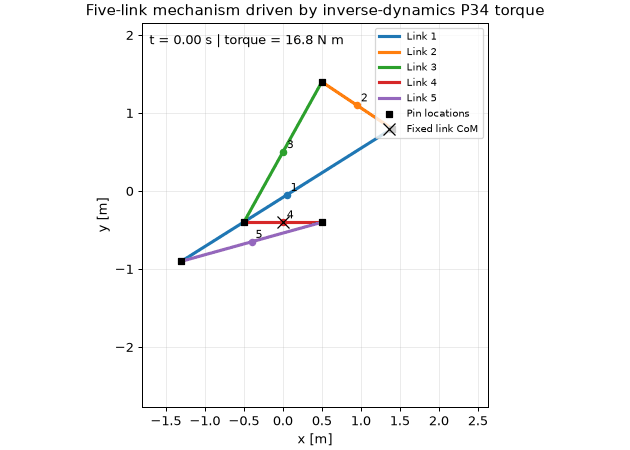

In [54]:
inverse_video_fps = driven_frame_rate
inverse_video_frame_count = int(round(driven_duration * inverse_video_fps))
inverse_video_frame_times = np.arange(inverse_video_frame_count, dtype=float) / inverse_video_fps
replay_sample_step = driven_sample_times[1] - driven_sample_times[0]
inverse_video_frame_indices = np.rint(inverse_video_frame_times / replay_sample_step).astype(int)
assert np.allclose(
    forward_replay_solution.t[inverse_video_frame_indices],
    inverse_video_frame_times,
    atol=1e-12,
    rtol=0.0,
)

replay_center_history = np.stack([
    forward_replay_q[3 * body:3 * body + 2, :].T
    for body in range(body_count)
])
replay_pin_history = np.asarray([
    joint_positions_at(forward_replay_q[:, sample_index])
    for sample_index in range(forward_replay_solution.t.size)
])
replay_positions = np.concatenate((
    replay_center_history.reshape(-1, 2),
    replay_pin_history.reshape(-1, 2),
))
replay_margin = 0.5
replay_x_limits = (
    replay_positions[:, 0].min() - replay_margin,
    replay_positions[:, 0].max() + replay_margin,
)
replay_y_limits = (
    replay_positions[:, 1].min() - replay_margin,
    replay_positions[:, 1].max() + replay_margin,
)

inverse_video_fig, inverse_video_ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
inverse_video_body_lines = []
inverse_video_center_markers = []
inverse_video_body_labels = []
for body in range(body_count):
    body_line, = inverse_video_ax.plot([], [], color=f'C{body}', linewidth=2.5, label=f'Link {body + 1}')
    center_marker, = inverse_video_ax.plot(
        [], [], marker='o', linestyle='None', color=f'C{body}', markersize=5
    )
    body_label = inverse_video_ax.text(0.0, 0.0, str(body + 1), fontsize=9)
    inverse_video_body_lines.append(body_line)
    inverse_video_center_markers.append(center_marker)
    inverse_video_body_labels.append(body_label)
inverse_video_pin_marker = inverse_video_ax.scatter(
    [], [], marker='s', color='black', s=22, label='Pin locations', zorder=4
)
inverse_video_fixed_marker, = inverse_video_ax.plot(
    [], [], marker='x', linestyle='None', color='black', markersize=9, label='Fixed link CoM'
)
inverse_video_time_label = inverse_video_ax.text(
    0.02, 0.97, '', transform=inverse_video_ax.transAxes, va='top'
)
inverse_video_ax.set_xlim(*replay_x_limits)
inverse_video_ax.set_ylim(*replay_y_limits)
inverse_video_ax.set_aspect('equal', adjustable='box')
inverse_video_ax.set_xlabel('x [m]')
inverse_video_ax.set_ylabel('y [m]')
inverse_video_ax.set_title('Five-link mechanism driven by inverse-dynamics P34 torque')
inverse_video_ax.grid(True, alpha=0.25)
inverse_video_ax.legend(loc='upper right', fontsize=8)


def update_P34_forward_replay_movie(frame_number):
    sample_index = inverse_video_frame_indices[frame_number]
    q = forward_replay_q[:, sample_index]
    pose = q.reshape(body_count, 3)
    for body in range(body_count):
        center = pose[body, :2]
        points = body_attachment_points(system, q, body)
        point_order = np.argsort(
            np.arctan2(points[:, 1] - center[1], points[:, 0] - center[0])
        )
        outline = points[point_order]
        if len(outline) > 2:
            outline = np.vstack((outline, outline[0]))
        inverse_video_body_lines[body].set_data(outline[:, 0], outline[:, 1])
        inverse_video_center_markers[body].set_data([center[0]], [center[1]])
        inverse_video_body_labels[body].set_position((center[0] + 0.05, center[1] + 0.05))
    inverse_video_pin_marker.set_offsets(joint_positions_at(q))
    inverse_video_fixed_marker.set_data([q[9]], [q[10]])
    replay_time = forward_replay_solution.t[sample_index]
    replay_torque = float(torque_history_interpolator_P34(replay_time))
    inverse_video_time_label.set_text(
        f't = {replay_time:.2f} s | torque = {replay_torque:.1f} N m'
    )
    return (
        *inverse_video_body_lines,
        *inverse_video_center_markers,
        *inverse_video_body_labels,
        inverse_video_pin_marker,
        inverse_video_fixed_marker,
        inverse_video_time_label,
    )


update_P34_forward_replay_movie(0)
inverse_replay_movie = FuncAnimation(
    inverse_video_fig,
    update_P34_forward_replay_movie,
    frames=inverse_video_frame_count,
    interval=1000 / inverse_video_fps,
    repeat=False,
    blit=False,
)
inverse_replay_movie_path = Path.cwd() / 'constrained_five_link_P34_inverse_replay_4s.gif'
inverse_replay_movie.save(
    inverse_replay_movie_path,
    writer=PillowWriter(fps=inverse_video_fps),
    dpi=90,
)
plt.close(inverse_video_fig)

with PILImage.open(inverse_replay_movie_path) as saved_inverse_replay_movie:
    inverse_replay_saved_frames = saved_inverse_replay_movie.n_frames
    inverse_replay_duration_ms = sum(
        saved_inverse_replay_movie.seek(frame_index)
        or saved_inverse_replay_movie.info.get('duration', 0)
        for frame_index in range(inverse_replay_saved_frames)
    )
assert inverse_replay_saved_frames == inverse_video_frame_count
assert inverse_replay_duration_ms == int(driven_duration * 1000)
print(f'Saved forward-replay animation: {inverse_replay_movie_path.resolve()}')
print(
    f'Duration: {inverse_replay_duration_ms / 1000:.2f} s | '
    f'Frames: {inverse_replay_saved_frames} | FPS: {inverse_video_fps} | '
    f'Size: {inverse_replay_movie_path.stat().st_size:,} bytes'
)
display(NotebookImage(filename=str(inverse_replay_movie_path)))

## PID hold at pin P34

### Controlled output and Jacobian

The actuator regulates the relative pin angle

$$
q_{34}=\theta_3-\theta_4, \qquad J_{34}=\frac{\partial q_{34}}{\partial q}.
$$

In the body-ordered Cartesian vector, `J_34` is a `1 x 15` row: it is zero except for `+1` in the `theta_3` column and `-1` in the `theta_4` column. Thus `q34_dot = J_34*qdot`. This output is linear, so its Jacobian is constant and its acceleration bias is zero. Positive motor torque acts along `B_34 = J_34.T`.

### Fixed-setpoint PID

The desired coordinate is the initial relative angle

$$
q_{34,0}=J_{34}q(0), \qquad e=q_{34}-q_{34,0}, \qquad \dot e=\dot q_{34}.
$$

With this error sign, positive error means the relative angle is above its desired value, so the PID feedback torque is negative:

$$
u_{PID}=-(K_p e+K_i z+K_d\dot e), \qquad \dot z=e.
$$

For this fixed hold test the feedforward is zero: the inverse-replay torque belongs to a moving reference and would drive against a constant setpoint. The total command is `u_34 = clip(0 + u_PID, -u_max, u_max)`. Conditional integration pauses only if the command is saturated and the error would push farther into saturation. Baumgarte terms separately maintain the 13 pin/ground constraints; PID controls only the P34 output, not the second mechanism degree of freedom. The gains and `+/-100 N m` torque cap remain illustrative, not hardware-tuned values.

In [55]:
pid_duration = driven_duration
pid_sample_times = driven_sample_times.copy()
q34_0 = float((relative_angle_jacobian_P34 @ q0)[0])
pid_kp_N_m_per_rad = 200.0
pid_ki_N_m_per_rad_s = 10.0
pid_kd_N_m_s_per_rad = 60.0
pid_torque_limit_N_m = 100.0
pid_feedforward_torque_hold_N_m = 0.0

# Perturb motor-relative rate while remaining tangent to all holonomic constraints.
pid_initial_rate_perturbation_rad_s = 0.15
pid_tangent_trial = np.zeros(coordinate_count)
pid_tangent_trial[3 * link_3 + 2] = 1.0
pid_tangent_direction = system.project_velocities(q0, pid_tangent_trial)
pid_tangent_output_rate = float((relative_angle_jacobian_P34 @ pid_tangent_direction)[0])
assert abs(pid_tangent_output_rate) > 1e-12
pid_initial_qdot = (
    qdot0
    + pid_initial_rate_perturbation_rad_s * pid_tangent_direction / pid_tangent_output_rate
)
pid_initial_state = np.concatenate((q0, pid_initial_qdot, [0.0]))


def evaluate_P34_pid(q, qdot, integral_error):
    relative_angle = float((relative_angle_jacobian_P34 @ q)[0])
    relative_rate = float((relative_angle_jacobian_P34 @ qdot)[0])
    angle_error = relative_angle - q34_0
    rate_error = relative_rate

    pid_correction_torque = -(
        pid_kp_N_m_per_rad * angle_error
        + pid_ki_N_m_per_rad_s * integral_error
        + pid_kd_N_m_s_per_rad * rate_error
    )
    unsaturated_total_torque = pid_feedforward_torque_hold_N_m + pid_correction_torque
    motor_torque = float(np.clip(
        unsaturated_total_torque,
        -pid_torque_limit_N_m,
        pid_torque_limit_N_m,
    ))
    pushing_further_into_saturation = (
        (unsaturated_total_torque > pid_torque_limit_N_m and angle_error < 0.0)
        or (unsaturated_total_torque < -pid_torque_limit_N_m and angle_error > 0.0)
    )
    integral_rate = 0.0 if pushing_further_into_saturation else angle_error
    return motor_torque, angle_error, integral_rate, pid_feedforward_torque_hold_N_m, pid_correction_torque


def P34_pid_state_derivative(time, augmented_state):
    q = augmented_state[:coordinate_count]
    qdot = augmented_state[coordinate_count:2 * coordinate_count]
    integral_error = augmented_state[-1]
    motor_torque, _, integral_rate, _, _ = evaluate_P34_pid(q, qdot, integral_error)

    phi, jac = system.constraints_and_jacobian(q)
    phi_dot = jac @ qdot
    constraint_rhs = (
        -system.jdot_qdot(q, qdot)
        - 2.0 * inverse_baumgarte_zeta * inverse_baumgarte_omega_rad_s * phi_dot
        - inverse_baumgarte_omega_rad_s**2 * phi
    )
    kkt = np.block([
        [system.mass_matrix, jac.T],
        [jac, np.zeros((constraint_count, constraint_count))],
    ])
    rhs = np.concatenate((
        system.generalized_forces(q, qdot, time) + actuator_map_P34 * motor_torque,
        constraint_rhs,
    ))
    solution = np.linalg.solve(kkt, rhs)
    qddot = solution[:coordinate_count]
    return np.concatenate((qdot, qddot, [integral_rate]))

### Integrate the PID-controlled mechanism

Augment the mechanical state with the PID integral error, then integrate the constrained dynamics with the PID torque applied through the P34 actuator map. Baumgarte terms remain in the constraint equations; they are not part of the PID law.

In [56]:
pid_response_solution = solve_ivp(
    P34_pid_state_derivative,
    (0.0, pid_duration),
    pid_initial_state,
    t_eval=pid_sample_times,
    rtol=1e-9,
    atol=1e-11,
    max_step=0.005,
)
if not pid_response_solution.success:
    raise RuntimeError(pid_response_solution.message)

pid_response_q = pid_response_solution.y[:coordinate_count, :]
pid_response_qdot = pid_response_solution.y[coordinate_count:2 * coordinate_count, :]
pid_integral_history = pid_response_solution.y[-1, :]
pid_torque_history_N_m = np.empty(pid_response_solution.t.size)
pid_feedforward_torque_N_m = np.empty(pid_response_solution.t.size)
pid_correction_torque_N_m = np.empty(pid_response_solution.t.size)
pid_relative_angle_error_rad = np.empty(pid_response_solution.t.size)
for sample_index in range(pid_response_solution.t.size):
    (
        pid_torque_history_N_m[sample_index],
        pid_relative_angle_error_rad[sample_index],
        _,
        pid_feedforward_torque_N_m[sample_index],
        pid_correction_torque_N_m[sample_index],
    ) = evaluate_P34_pid(
        pid_response_q[:, sample_index],
        pid_response_qdot[:, sample_index],
        pid_integral_history[sample_index],
    )

### Measure tracking and constraint errors

Compare the controlled output with the unactuated baseline, then check pin closure and fixed-link pose separately. This keeps controller performance distinct from the numerical constraint-stabilization checks.

In [57]:
baseline_relative_angle = (
    relative_angle_jacobian_P34 @ solution.y[:coordinate_count, :]
).reshape(-1)
baseline_relative_angle_at_pid_times = np.interp(
    pid_response_solution.t,
    solution.t,
    baseline_relative_angle,
)
baseline_relative_angle_error_rad = baseline_relative_angle_at_pid_times - q34_0

pid_pin_position_errors_m = []
pid_ground_translation_errors_m = []
pid_ground_angle_errors_rad = []
for sample_index in range(pid_response_solution.t.size):
    sample_phi, _ = system.constraints_and_jacobian(pid_response_q[:, sample_index])
    pid_pin_position_errors_m.append(np.linalg.norm(sample_phi[:10], ord=np.inf))
    pid_ground_translation_errors_m.append(np.linalg.norm(sample_phi[10:12], ord=np.inf))
    pid_ground_angle_errors_rad.append(np.linalg.norm(sample_phi[12:]))

max_pid_pin_position_error_m = max(pid_pin_position_errors_m)
max_pid_ground_translation_error_m = max(pid_ground_translation_errors_m)
max_pid_ground_angle_error_rad = max(pid_ground_angle_errors_rad)
assert max_pid_pin_position_error_m < 1e-8
assert max_pid_ground_translation_error_m < 1e-10
assert max_pid_ground_angle_error_rad < 1e-10
assert np.allclose(
    pid_torque_history_N_m,
    np.clip(
        pid_feedforward_torque_N_m + pid_correction_torque_N_m,
        -pid_torque_limit_N_m,
        pid_torque_limit_N_m,
    ),
)

print(f'P34 hold target q34_0: {q34_0:.6f} rad ({np.degrees(q34_0):.3f} deg)')
print(f'Error convention: e = q34 - q34_0')
print(f'Illustrative total-torque cap: +/-{pid_torque_limit_N_m:.1f} N m')
print(f'Max P34 hold error with PID: {np.max(np.abs(pid_relative_angle_error_rad)):.3e} rad')
print(f'Max P34 hold error, unactuated baseline: {np.max(np.abs(baseline_relative_angle_error_rad)):.3e} rad')
print(f'Final P34 hold error: {pid_relative_angle_error_rad[-1]:.3e} rad')
print(f'Hold-bias feedforward torque: {pid_feedforward_torque_hold_N_m:.3f} N m')
print(f'PID correction range: {pid_correction_torque_N_m.min():.3f} to {pid_correction_torque_N_m.max():.3f} N m')
print(f'Total P34 torque range: {pid_torque_history_N_m.min():.3f} to {pid_torque_history_N_m.max():.3f} N m')
print(f'Max PID-run pin closure error: {max_pid_pin_position_error_m:.3e} m')
print(f'Max PID-run grounded translation error: {max_pid_ground_translation_error_m:.3e} m')
print(f'Max PID-run grounded angle error: {max_pid_ground_angle_error_rad:.3e} rad')

P34 hold target q34_0: -2.077895 rad (-119.055 deg)
Error convention: e = q34 - q34_0
Illustrative total-torque cap: +/-100.0 N m
Max P34 hold error with PID: 1.300e-01 rad
Max P34 hold error, unactuated baseline: 4.837e+00 rad
Final P34 hold error: -1.092e-01 rad
Hold-bias feedforward torque: 0.000 N m
PID correction range: -10.548 to 34.457 N m
Total P34 torque range: -10.548 to 34.457 N m
Max PID-run pin closure error: 1.750e-11 m
Max PID-run grounded translation error: 4.423e-18 m
Max PID-run grounded angle error: 4.403e-18 rad


### Compare regulation response

Overlay the P34 angle error from the PID run and the gravity-only baseline. The comparison is for this initial state and gain set; it is not a global stability result.

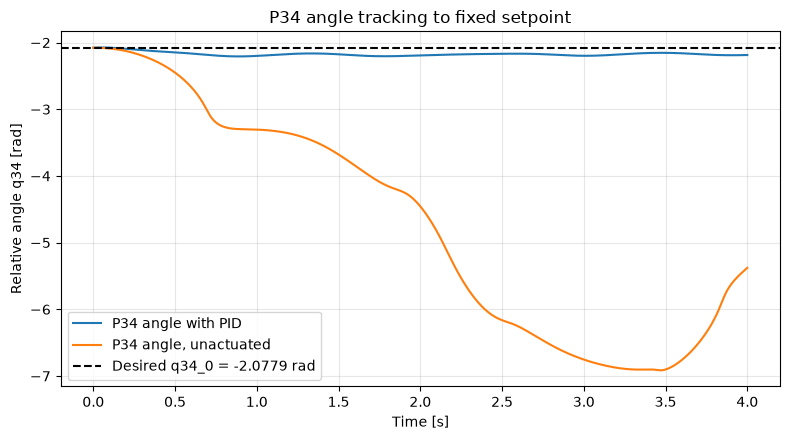

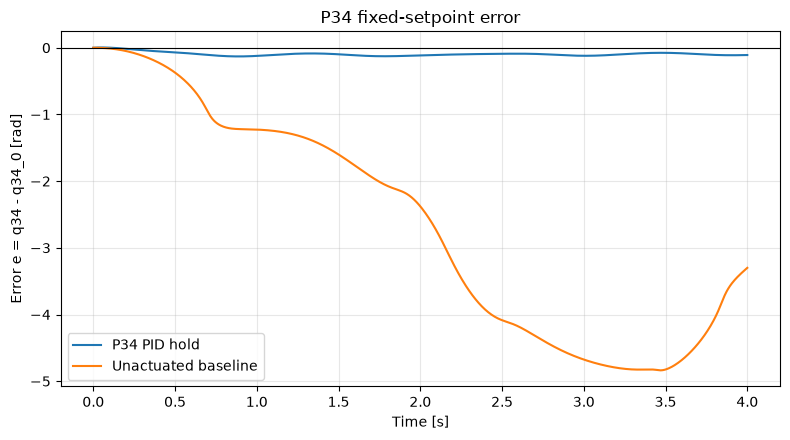

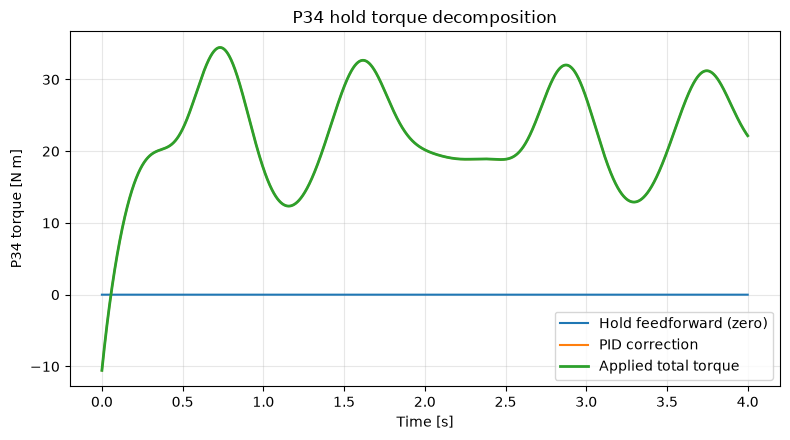

In [58]:
pid_relative_angle_history_rad = (
    relative_angle_jacobian_P34 @ pid_response_q
).reshape(-1)
baseline_relative_angle_history_at_pid_times_rad = np.interp(
    pid_response_solution.t,
    solution.t,
    baseline_relative_angle,
)

plt.figure(figsize=(8, 4.5))
plt.plot(
    pid_response_solution.t,
    pid_relative_angle_history_rad,
    label='P34 angle with PID',
)
plt.plot(
    pid_response_solution.t,
    baseline_relative_angle_history_at_pid_times_rad,
    label='P34 angle, unactuated',
)

plt.axhline(
    q34_0,
    color='black',
    linestyle='--',
    label=f'Desired q34_0 = {q34_0:.4f} rad',
)
plt.xlabel('Time [s]')
plt.ylabel('Relative angle q34 [rad]')
plt.title('P34 angle tracking to fixed setpoint')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
plt.plot(pid_response_solution.t, pid_relative_angle_error_rad, label='P34 PID hold')
plt.plot(pid_response_solution.t, baseline_relative_angle_error_rad, label='Unactuated baseline')
plt.axhline(0.0, color='black', linewidth=0.8)
plt.xlabel('Time [s]')
plt.ylabel('Error e = q34 - q34_0 [rad]')
plt.title('P34 fixed-setpoint error')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
plt.plot(pid_response_solution.t, pid_feedforward_torque_N_m, label='Hold feedforward (zero)')
plt.plot(pid_response_solution.t, pid_correction_torque_N_m, label='PID correction')
plt.plot(pid_response_solution.t, pid_torque_history_N_m, label='Applied total torque', linewidth=2)
plt.xlabel('Time [s]')
plt.ylabel('P34 torque [N m]')
plt.title('P34 hold torque decomposition')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Interpreting this run

The hold target is `q34_0 = -2.077895 rad` (`-119.055 deg`), the initial relative angle, and the plotted error is `e = q34 - q34_0`. A constraint-compatible `0.15 rad/s` initial relative-rate disturbance is applied. The maximum absolute hold error is `0.130 rad` and the final error is `-0.109 rad`, compared with `4.837 rad` maximum deviation for the unactuated baseline. The moving inverse-replay torque is intentionally excluded: it belongs to a changing trajectory, not this fixed-angle hold. Thus hold feedforward is zero and total motor torque is the signed PID correction, ranging from `-10.548` to `34.456 N m` (below the illustrative `+/-100 N m` cap). Maximum pin closure error is `1.740e-11 m`; grounded translation and angle errors are `4.419e-18 m` and `4.403e-18 rad`. Those small constraint errors come from Baumgarte stabilization. One motor regulates P34 only and does not control the mechanism's other degree of freedom.

### Animate the PID-regulated response

The animation shows the PID-controlled trajectory and annotates each frame with the P34 angle error and commanded torque. It is a one-output regulation example; motion in the unactuated degree of freedom is not claimed to be stabilized.

Saved PID hold animation: C:\Users\Mourad\Desktop\multybody systems\constrained_five_link_P34_PID_4s.gif
Duration: 4.00 s | Frames: 80 | FPS: 20 | Size: 589,403 bytes


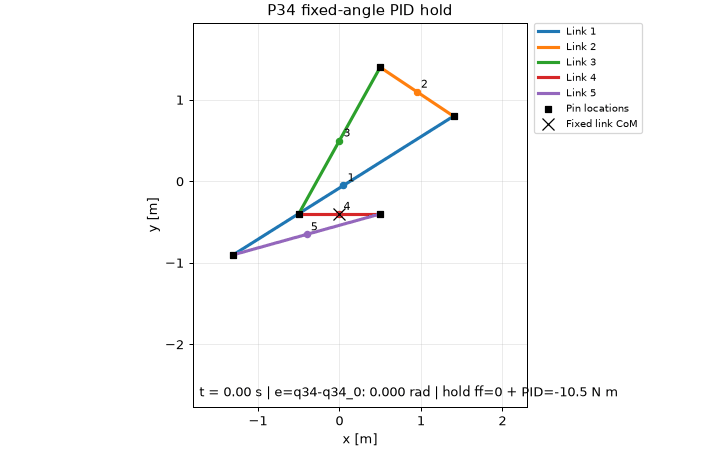

In [59]:
pid_video_fps = driven_frame_rate
pid_video_frame_count = int(round(pid_duration * pid_video_fps))
pid_video_frame_times = np.arange(pid_video_frame_count, dtype=float) / pid_video_fps
pid_video_sample_step = pid_sample_times[1] - pid_sample_times[0]
pid_video_frame_indices = np.rint(pid_video_frame_times / pid_video_sample_step).astype(int)
assert np.allclose(
    pid_response_solution.t[pid_video_frame_indices],
    pid_video_frame_times,
    atol=1e-12,
    rtol=0.0,
)

pid_video_pin_history = np.asarray([
    joint_positions_at(pid_response_q[:, sample_index])
    for sample_index in range(pid_response_solution.t.size)
])
pid_video_centers = np.stack([
    pid_response_q[3 * body:3 * body + 2, :].T
    for body in range(body_count)
])
pid_video_positions = np.concatenate((
    pid_video_centers.reshape(-1, 2),
    pid_video_pin_history.reshape(-1, 2),
))
pid_video_margin = 0.5
pid_video_x_limits = (
    pid_video_positions[:, 0].min() - pid_video_margin,
    pid_video_positions[:, 0].max() + pid_video_margin,
)
pid_video_y_limits = (
    pid_video_positions[:, 1].min() - pid_video_margin,
    pid_video_positions[:, 1].max() + pid_video_margin,
)

pid_video_fig, pid_video_ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
pid_video_lines = []
pid_video_centroid_markers = []
pid_video_labels = []
for body in range(body_count):
    body_line, = pid_video_ax.plot([], [], color=f'C{body}', linewidth=2.5, label=f'Link {body + 1}')
    centroid_marker, = pid_video_ax.plot(
        [], [], marker='o', linestyle='None', color=f'C{body}', markersize=5
    )
    body_label = pid_video_ax.text(0.0, 0.0, str(body + 1), fontsize=9)
    pid_video_lines.append(body_line)
    pid_video_centroid_markers.append(centroid_marker)
    pid_video_labels.append(body_label)
pid_video_pin_marker = pid_video_ax.scatter(
    [], [], marker='s', color='black', s=22, label='Pin locations', zorder=4
)
pid_video_fixed_marker, = pid_video_ax.plot(
    [], [], marker='x', linestyle='None', color='black', markersize=9, label='Fixed link CoM'
)
pid_video_text = pid_video_ax.text(
    0.02, 0.02, '', transform=pid_video_ax.transAxes, va='bottom'
)
pid_video_ax.set_xlim(*pid_video_x_limits)
pid_video_ax.set_ylim(*pid_video_y_limits)
pid_video_ax.set_aspect('equal', adjustable='box')
pid_video_ax.set_xlabel('x [m]')
pid_video_ax.set_ylabel('y [m]')
pid_video_ax.set_title('P34 fixed-angle PID hold')
pid_video_ax.grid(True, alpha=0.25)
pid_video_ax.legend(
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    fontsize=8,
    borderaxespad=0.0,
)


def update_P34_pid_movie(frame_number):
    sample_index = pid_video_frame_indices[frame_number]
    q = pid_response_q[:, sample_index]
    pose = q.reshape(body_count, 3)
    for body in range(body_count):
        center = pose[body, :2]
        points = body_attachment_points(system, q, body)
        point_order = np.argsort(
            np.arctan2(points[:, 1] - center[1], points[:, 0] - center[0])
        )
        outline = points[point_order]
        if len(outline) > 2:
            outline = np.vstack((outline, outline[0]))
        pid_video_lines[body].set_data(outline[:, 0], outline[:, 1])
        pid_video_centroid_markers[body].set_data([center[0]], [center[1]])
        pid_video_labels[body].set_position((center[0] + 0.05, center[1] + 0.05))
    pid_video_pin_marker.set_offsets(joint_positions_at(q))
    pid_video_fixed_marker.set_data([q[9]], [q[10]])
    pid_time = pid_response_solution.t[sample_index]
    pid_video_text.set_text(
        f't = {pid_time:.2f} s | e=q34-q34_0: {pid_relative_angle_error_rad[sample_index]:.3f} rad | '
        f'hold ff=0 + PID={pid_correction_torque_N_m[sample_index]:.1f} N m'
    )
    return (
        *pid_video_lines,
        *pid_video_centroid_markers,
        *pid_video_labels,
        pid_video_pin_marker,
        pid_video_fixed_marker,
        pid_video_text,
    )


update_P34_pid_movie(0)
pid_response_movie = FuncAnimation(
    pid_video_fig,
    update_P34_pid_movie,
    frames=pid_video_frame_count,
    interval=1000 / pid_video_fps,
    repeat=False,
    blit=False,
)
pid_response_movie_path = Path.cwd() / 'constrained_five_link_P34_PID_4s.gif'
pid_response_movie.save(
    pid_response_movie_path,
    writer=PillowWriter(fps=pid_video_fps),
    dpi=90,
)
plt.close(pid_video_fig)

with PILImage.open(pid_response_movie_path) as saved_pid_response_movie:
    pid_response_saved_frames = saved_pid_response_movie.n_frames
    pid_response_duration_ms = sum(
        saved_pid_response_movie.seek(frame_index)
        or saved_pid_response_movie.info.get('duration', 0)
        for frame_index in range(pid_response_saved_frames)
    )
assert pid_response_saved_frames == pid_video_frame_count
assert pid_response_duration_ms == int(pid_duration * 1000)
print(f'Saved PID hold animation: {pid_response_movie_path.resolve()}')
print(
    f'Duration: {pid_response_duration_ms / 1000:.2f} s | '
    f'Frames: {pid_response_saved_frames} | FPS: {pid_video_fps} | '
    f'Size: {pid_response_movie_path.stat().st_size:,} bytes'
)
display(NotebookImage(filename=str(pid_response_movie_path)))